<a href="https://colab.research.google.com/github/despoileralert/DSA2101-Project/blob/main/Randomforestnotrees_Datathon_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Required Libraries

In [ ]:
!pip install kmodes
!pip install streamlit -q
!pip install gower
!pip install tqdm
#!pip install localtunnel -q
# Data handling and visualization
# import kagglehub
import pandas as pd
import numpy as np
import seaborn as sns
import re
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
import seaborn as sns
import missingno as msno
import networkx as nx
import time
import pickle
import warnings
import random
import gower

# Statistical analysis
import scipy.stats as stats

# Machine learning utilities
from sklearn.preprocessing import StandardScaler, RobustScaler, MaxAbsScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import matthews_corrcoef, silhouette_score, davies_bouldin_score
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, RobustScaler
from sklearn.compose import ColumnTransformer
from scipy.spatial.distance import squareform
from kmodes.kprototypes import KPrototypes
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from umap import UMAP
from hdbscan import HDBSCAN
from itertools import product
from sklearn.preprocessing import MinMaxScaler
from tqdm import tqdm




warnings.filterwarnings("ignore")

random.seed(1000)


pd.set_option("display.max_columns", 100)
# path = kagglehub.dataset_download("imakash3011/customer-personality-analysis")

# print("Path to dataset files:", path)

## 1B: Importing Data

To ensure compatibility across different environments, if you're running locally, upload the dataset into the project folder. Otherwise, if you're using Google Colab, upload it into the "content" folder. After uploading, the following code will read the file and display basic information about the dataset.


In [ ]:
data = pd.read_excel("champions_group_data.xlsx")
#data = pd.read_csv("champions_group_data.csv")
data.info()

# data["Manufacturing Status"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8559 entries, 0 to 8558
Data columns (total 72 columns):
 #   Column                                 Non-Null Count  Dtype         
---  ------                                 --------------  -----         
 0   DUNS Number                            8559 non-null   int64         
 1   Company Sites                          8559 non-null   object        
 2   Website                                625 non-null    object        
 3   Address Line 1                         8216 non-null   object        
 4   City                                   8045 non-null   object        
 5   State                                  8044 non-null   object        
 6   State Or Province Abbreviation         7824 non-null   object        
 7   Postal Code                            8062 non-null   float64       
 8   Country                                8559 non-null   object        
 9   Phone Number                           1674 non-null   float64 

## 1C: Preliminary Analysis of columns to keep / drop

We first remove all columns with more than or equal to 50% (Threshold = 0.5) missing values since it is a sizable number and is unlikely to be able to be well interpolated.

Next, we examined the number of unique values count, duplicates or redundant columns from the data set and then use domain knowledge to identify which variables likely do NOT contribute much to company intelligence.

Drop columns:
1. Address Line 1 (Location, too specific)
2. State (Too broad)
3. State Or Province Abbreviation (same as 3.)
4. Postal Code (Same as 2.)
5. Country (99.8% China, only 11 are from Indonesia)
6. Region (Just Asia)
7. Ownership Type (99% Private)
8. Employees Single Site (Same as Employees Total)
9. SIC Description (Same meaning as SIC Code)
10. Parent Street Address (Reason similar to 2.)
11. Parent State/Province (Reason similar to 3.)
12. Parent State/Province Abbreviation (Reason similar to 3.)
13. Parent Postal Code (Reason similar to 5.)
14. Parent Country/Region (Reason similar to 6.)
15. Global Ultimate Street Address (Reason similar to 2.)
16. Global Ultimate State/Province (Reason similar to 3.)
17. Ultimate State/Province Abbreviation (Reason similar to 3.)
18. Global Ultimate Postal Code (Reason similar to 2.)
19. Domestic Ultimate Street Address (Reason similar to 2.)
20. Domestic Ultimate State/Province Name (Reason similar to 3.)
21. Domestic Ultimate State Abbreviation (Reason similar to 3.)
22. Domestic Ultimate Postal Code (Reason similar to 2.)
23. Registration Number (Unique identifier)
24. Company Status (Active/Inactive) (All are active)
25. Fiscal Year End (All 2031)
26. 8-Digit SIC Code (Redundant, SIC code is sufficient)
27. 8-Digit SIC Description (Reason similar to 9.)
28. Phone Number (Arbitrarily assigned, country codes are already captured in country)
29. Lattitude (Reason similar to 1.)
30. Longitude (Reason similar to 1.)
31. ANZSIC Description (Reason similar to 9.)
32. Company Description (Reason similar to 9.)

Keep columns:
1. DUNS Number (Unique identifier, likely does not contribute much to business intelligence BUT is useful for determining "near-duplicates")
2. Company Sites
3. Parent Company
4. City
5. Entity Type
6. Employees Total (100% match with single site)
7. Revenue (USD)
8. SIC Code
9. Year Found
10. Parents City (Use statistical method to check importance later)
11. Global Ultimate City Name (Same reason as 10.)
12. Domestic Ultimate City Name (Same reasaon as 10.)
13. Domestic Ultimate Company (Drop after transforming)
14. Global Ultimate Company (Matches between Global and Domestic ultimate company is 8436, use new transfromed variable)
15. Global Ultimate Country Name (98.5% China, 130 are foreign BUT a foreign flag variable could potentially be valuable, apply statistical method to test before dropping)
16. Legal Status  (Domain knowledge, research)
17. Corporate Family Members
18. Market Value (USD)
19. IT Budget
20. IT spend
21. No. of PC
22. No. of Desktops
23. No. of Laptops
24. No. of Routers
25. No. of Servers
26. No. of Storage Devices
27. NAICS Code (Industry standard classification that replaced the SIC code in North America)
28. NACE Rev 2 Code (Industry standard classification that replaced the  SIC code in the Europian Union)
29. Ticker (Only 4 entries, but it's presence could be an important signifier)
30. Is Headquarters (Distinguishes between a centralised style of management vs otherwise)
31. Is Domestic Ultimate (Could be significant, it checks if they are the top of the local chain within the country though it is possible for there to be a higher company. In that case, it is either globally based or does not communicate directly to them)
32. Franchise Status (Boolean)
33. Manufacturing Status (Boolean, with all non-null values having 0 variance, can act as a binary flag variable)
34. ANZSIC Code (Industry standard classification that replaced the SIC code in Australia/New Zealand)
35. ISIC Rev 4 Code (Industry standard classification that replaced the SIC code, by the UN)
36. Registration Number Type (All 8 non-nulls are the same, 0 variance but it can be a binary flag variable)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8559 entries, 0 to 8558
Data columns (total 72 columns):
 #   Column                                 Non-Null Count  Dtype         
---  ------                                 --------------  -----         
 0   DUNS Number                            8559 non-null   int64         
 1   Company Sites                          8559 non-null   object        
 2   Website                                625 non-null    object        
 3   Address Line 1                         8216 non-null   object        
 4   City                                   8045 non-null   object        
 5   State                                  8044 non-null   object        
 6   State Or Province Abbreviation         7824 non-null   object        
 7   Postal Code                            8062 non-null   float64       
 8   Country                                8559 non-null   object        
 9   Phone Number                           1674 non-null   float64 

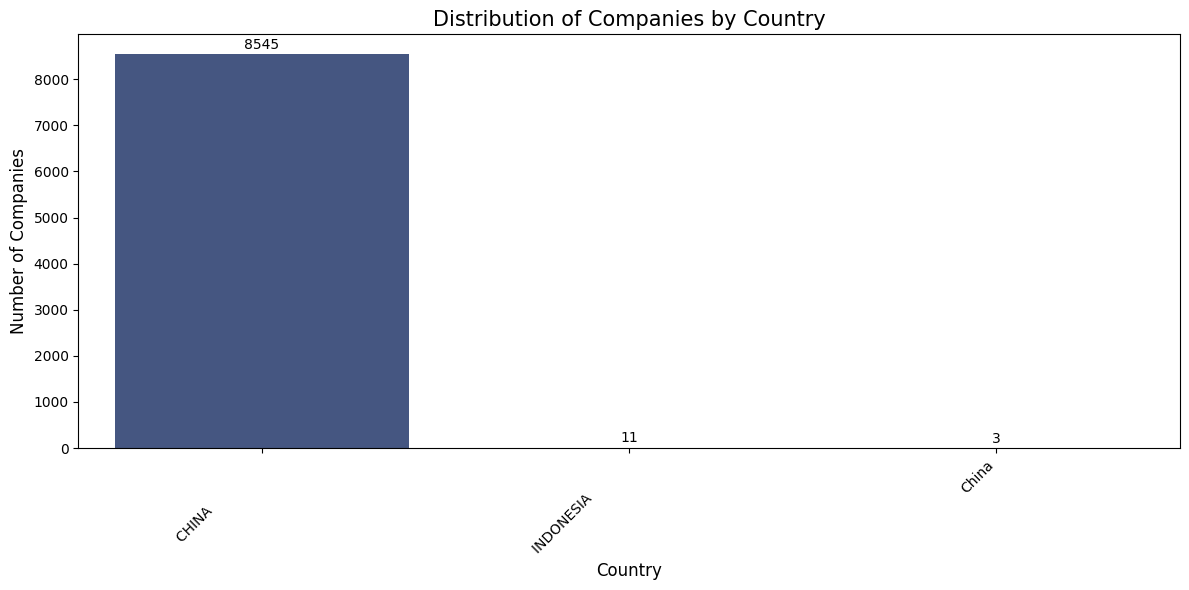

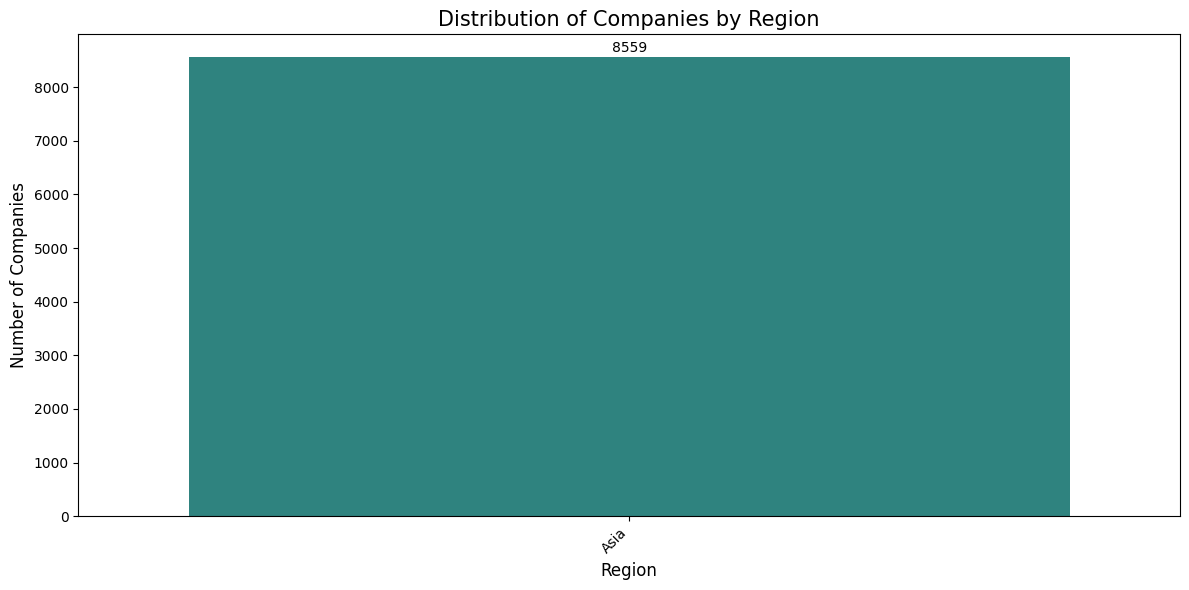

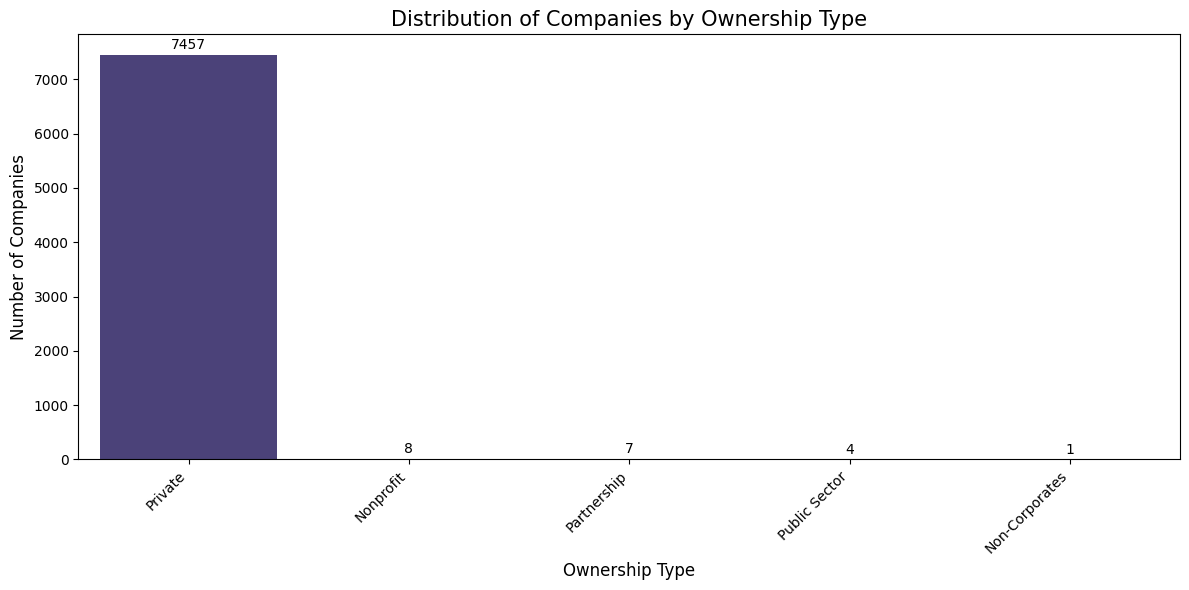

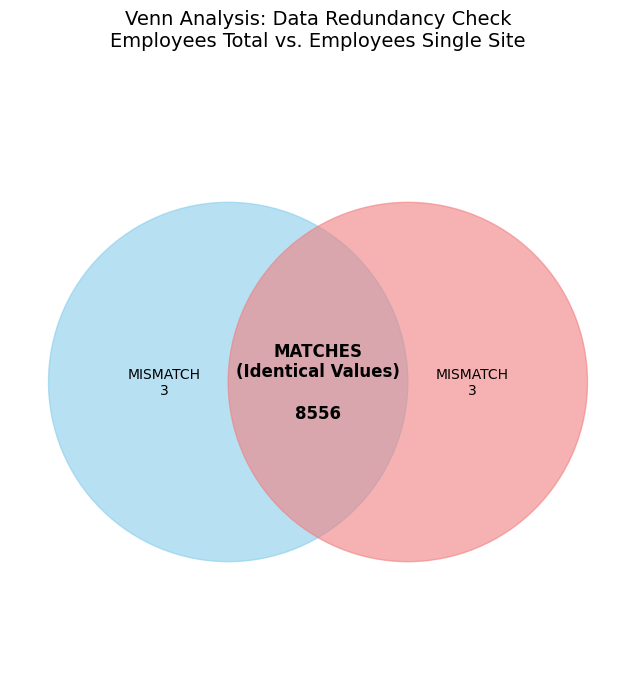

Analysis Complete: 8556 companies have identical values for both columns.


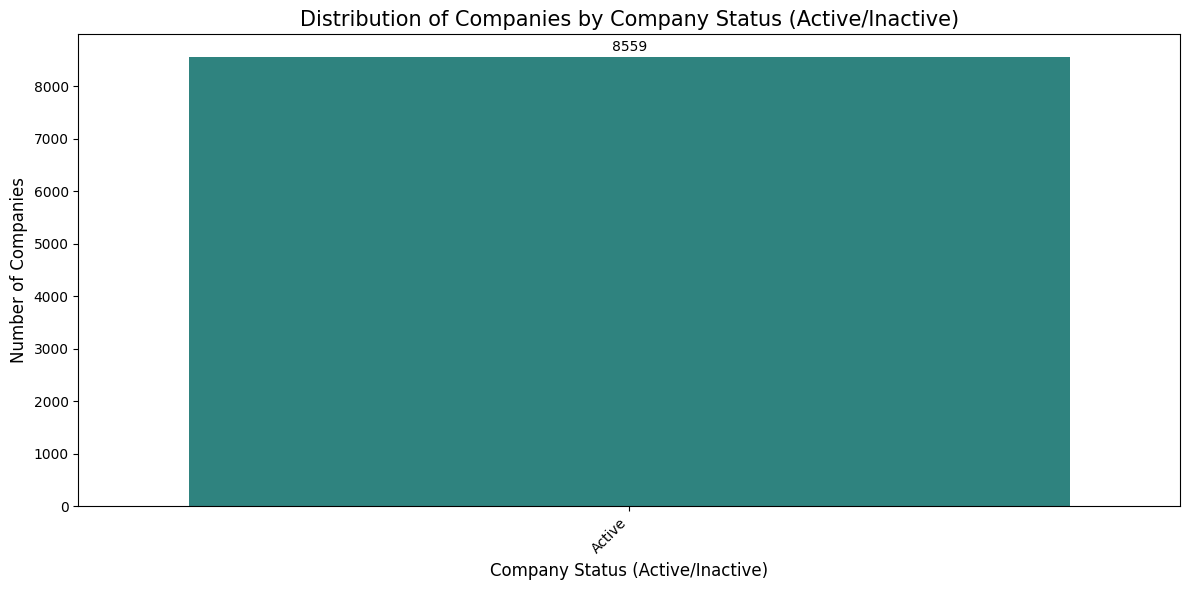

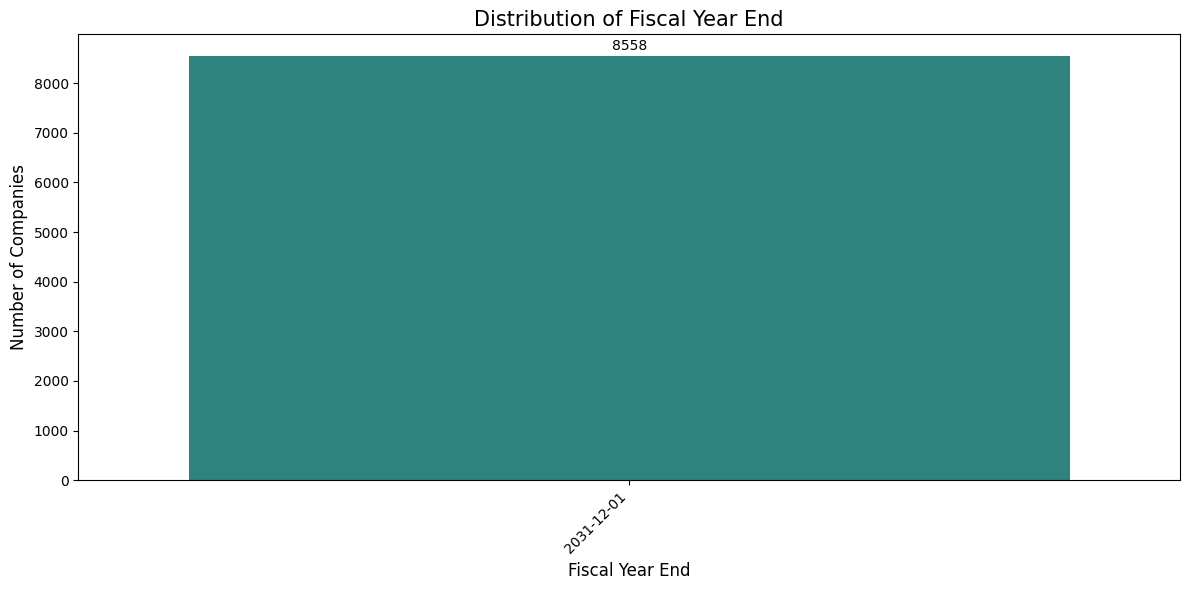

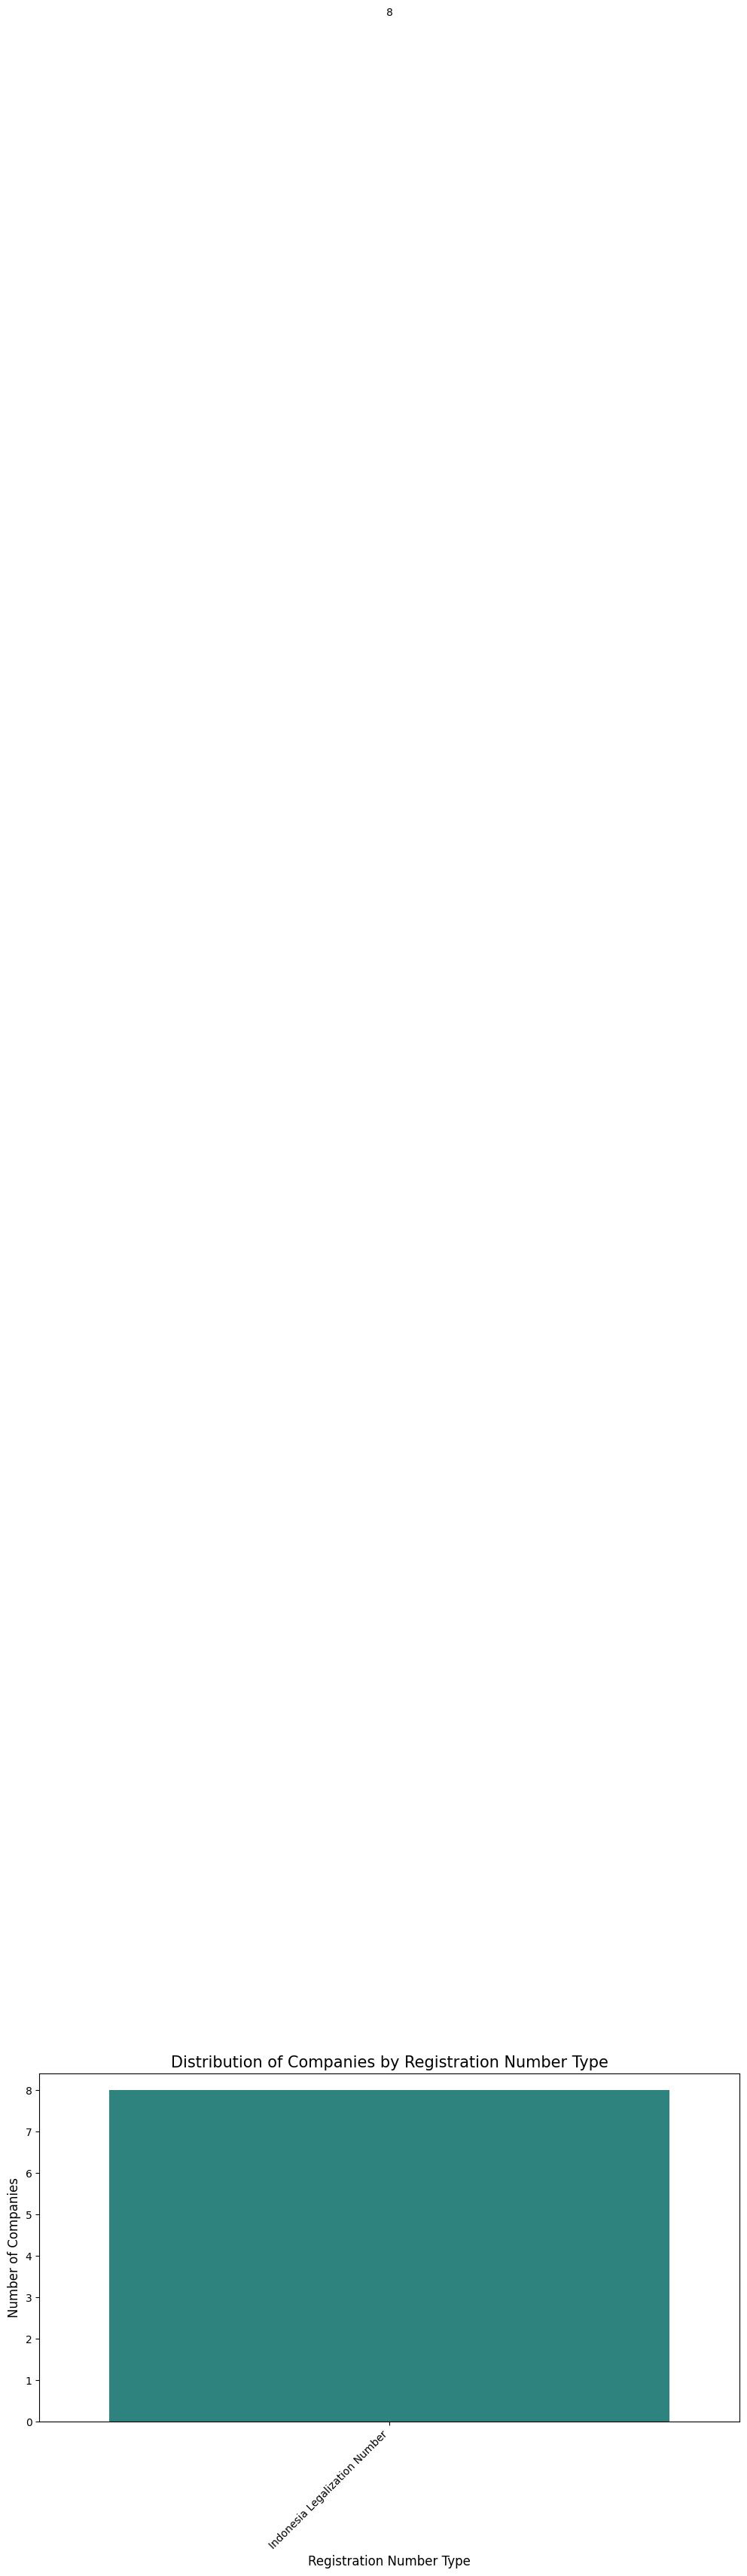

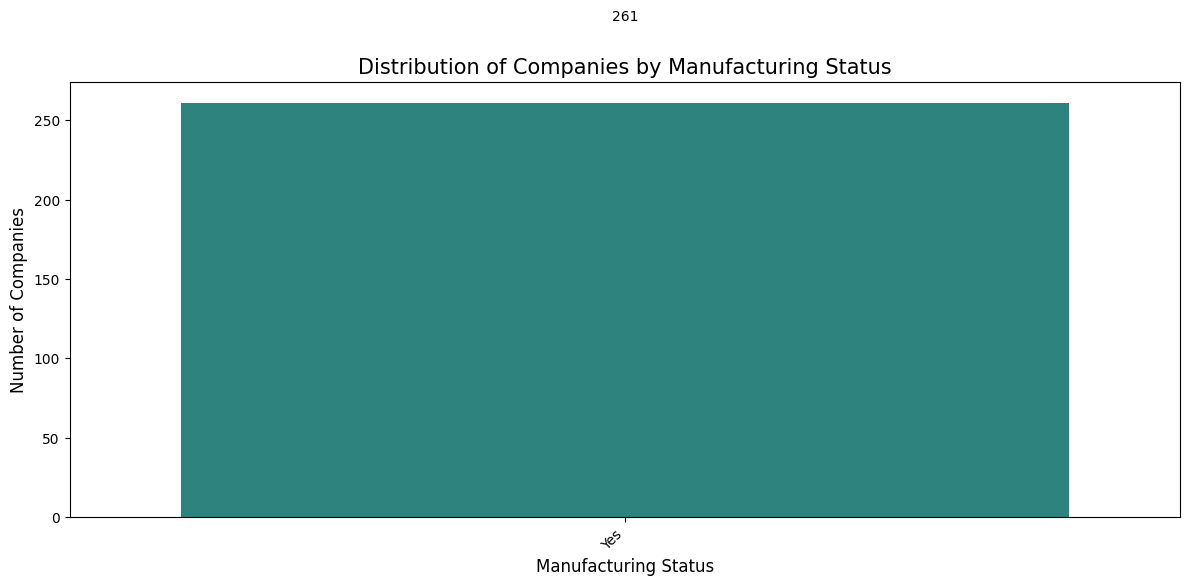

--- Cross-Verification Table ---
Ticker is Missing  False  True 
Ownership Type                 
Non-Corporates         0      1
Nonprofit              0      8
Partnership            0      7
Private                0   7457
Public Sector          4      0
NaN                    0   1082

Percentage of Private companies with missing Tickers: 100.00%


In [ ]:
# Section removed (Arbitrary threshold of 50%, unjustifiable since sparse data being present could be some sort of strong indicator)
# Set the threshold: 50% of the total number of rows
# thresh requires a minimum number of NON-NA values to keep the column
# threshold = len(data) * 0.5

# Drop columns that have more than 50% missing values
# data_cleaned = data.dropna(axis=1, thresh=threshold)
data_cleaned = data.copy()

# Check the results
data_cleaned.info()

# Analysis of Country distribution
data['Country'].value_counts()

# Calculate value counts
country_counts = data['Country'].value_counts()

# Create the plot
plt.figure(figsize=(12, 6))
sns.barplot(x=country_counts.index, y=country_counts.values, palette='viridis')

# Add labels and title
plt.title('Distribution of Companies by Country', fontsize=15)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Number of Companies', fontsize=12)

# Rotate labels for readability
plt.xticks(rotation=45, ha='right')

# Add data labels on top of bars
for i, v in enumerate(country_counts.values):
    plt.text(i, v + 50, str(v), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

###### Analysis of Region distribution
data['Region'].value_counts()

# Calculate value counts
Region_counts = data['Region'].value_counts()

# Create the plot
plt.figure(figsize=(12, 6))
sns.barplot(x=Region_counts.index, y=Region_counts.values, palette='viridis')

# Add labels and title
plt.title('Distribution of Companies by Region', fontsize=15)
plt.xlabel('Region', fontsize=12)
plt.ylabel('Number of Companies', fontsize=12)

# Rotate labels for readability
plt.xticks(rotation=45, ha='right')

# Add data labels on top of bars
for i, v in enumerate(Region_counts.values):
    plt.text(i, v + 50, str(v), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

###### Analysis of Ownership Type distribution
data['Ownership Type'].value_counts()

# Calculate value counts
Ownership_Type_counts = data['Ownership Type'].value_counts()

# Create the plot
plt.figure(figsize=(12, 6))
sns.barplot(x=Ownership_Type_counts.index, y=Ownership_Type_counts.values, palette='viridis')

# Add labels and title
plt.title('Distribution of Companies by Ownership Type', fontsize=15)
plt.xlabel('Ownership Type', fontsize=12)
plt.ylabel('Number of Companies', fontsize=12)

# Rotate labels for readability
plt.xticks(rotation=45, ha='right')

# Add data labels on top of bars
for i, v in enumerate(Ownership_Type_counts.values):
    plt.text(i, v + 50, str(v), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

##### Matches between 'Employees Total' and 'Employees Single Site'
# 1. Calculate the components for the Venn Diagram
# -----------------------------------------------
# Number of rows where both columns have the same value
matches = (data['Employees Total'] == data['Employees Single Site']).sum()

# Number of rows where they are different
mismatches = (data['Employees Total'] != data['Employees Single Site']).sum()

# Optional: Number of rows where data is missing in one but not the other
# (Assuming for this visual that both columns are mostly populated)

# 2. Create the Visual
# --------------------
fig, ax = plt.subplots(figsize=(8, 8))

# Draw two overlapping circles
circle_left = plt.Circle((-0.35, 0), 0.7, color='skyblue', alpha=0.6, label='Total Employees')
circle_right = plt.Circle((0.35, 0), 0.7, color='lightcoral', alpha=0.6, label='Single Site Employees')

ax.add_patch(circle_left)
ax.add_patch(circle_right)

# Set the plot limits and hide axes
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_aspect('equal')
plt.axis('off')

# 3. Add Text Annotations
# -----------------------
# The Overlap (Matches)
plt.text(0, 0, f"MATCHES\n(Identical Values)\n\n{matches}",
         ha='center', va='center', fontsize=12, fontweight='bold')

# The Left Side (Discrepancies/Multi-site)
plt.text(-0.6, 0, f"MISMATCH\n{mismatches}",
         ha='center', va='center', fontsize=10)

# The Right Side (Usually same as left in a column-to-column comparison)
plt.text(0.6, 0, f"MISMATCH\n{mismatches}",
         ha='center', va='center', fontsize=10)

plt.title("Venn Analysis: Data Redundancy Check\nEmployees Total vs. Employees Single Site", fontsize=14, pad=20)

# Save the plot
plt.savefig('employees_venn_analysis.png', bbox_inches='tight')
plt.show()

print(f"Analysis Complete: {matches} companies have identical values for both columns.")

##### Analysis of Company Status (Active/Inactive) distribution
data['Company Status (Active/Inactive)'].value_counts()

# Calculate value counts
Company_Status_Active_Inactive_counts = data['Company Status (Active/Inactive)'].value_counts()

# Create the plot
plt.figure(figsize=(12, 6))
sns.barplot(x=Company_Status_Active_Inactive_counts.index, y=Company_Status_Active_Inactive_counts.values, palette='viridis')

# Add labels and title
plt.title('Distribution of Companies by Company Status (Active/Inactive)', fontsize=15)
plt.xlabel('Company Status (Active/Inactive)', fontsize=12)
plt.ylabel('Number of Companies', fontsize=12)

# Rotate labels for readability
plt.xticks(rotation=45, ha='right')

# Add data labels on top of bars
for i, v in enumerate(Company_Status_Active_Inactive_counts.values):
    plt.text(i, v + 50, str(v), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

##### Analysis of Fiscal Year End distribution
data['Fiscal Year End'].value_counts()

# Calculate value counts
Fiscal_Year_End_counts = data['Fiscal Year End'].value_counts()

# Create the plot
plt.figure(figsize=(12, 6))
sns.barplot(x=Fiscal_Year_End_counts.index, y=Fiscal_Year_End_counts.values, palette='viridis')

# Add labels and title
plt.title('Distribution of Fiscal Year End', fontsize=15)
plt.xlabel('Fiscal Year End', fontsize=12)
plt.ylabel('Number of Companies', fontsize=12)

# Rotate labels for readability
plt.xticks(rotation=45, ha='right')

# Add data labels on top of bars
for i, v in enumerate(Fiscal_Year_End_counts.values):
    plt.text(i, v + 50, str(v), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

###### Analysis of Registration Number Type distribution
data['Registration Number Type'].value_counts()

# Calculate value counts
Registration_Number_Type_counts = data['Registration Number Type'].value_counts()

# Create the plot
plt.figure(figsize=(12, 6))
sns.barplot(x=Registration_Number_Type_counts.index, y=Registration_Number_Type_counts.values, palette='viridis')

# Add labels and title
plt.title('Distribution of Companies by Registration Number Type', fontsize=15)
plt.xlabel('Registration Number Type', fontsize=12)
plt.ylabel('Number of Companies', fontsize=12)

# Rotate labels for readability
plt.xticks(rotation=45, ha='right')

# Add data labels on top of bars
for i, v in enumerate(Registration_Number_Type_counts.values):
    plt.text(i, v + 50, str(v), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

###### Analysis of Manufacturing Status distribution
data['Legal Status'].value_counts()

# Calculate value counts
Manufacturing_Status_Type_counts = data['Manufacturing Status'].value_counts()

# Create the plot
plt.figure(figsize=(12, 6))
sns.barplot(x=Manufacturing_Status_Type_counts.index, y=Manufacturing_Status_Type_counts.values, palette='viridis')

# Add labels and title
plt.title('Distribution of Companies by Manufacturing Status', fontsize=15)
plt.xlabel('Manufacturing Status', fontsize=12)
plt.ylabel('Number of Companies', fontsize=12)

# Rotate labels for readability
plt.xticks(rotation=45, ha='right')

# Add data labels on top of bars
for i, v in enumerate(Manufacturing_Status_Type_counts.values):
    plt.text(i, v + 50, str(v), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

# Create a cross-tabulation of Ownership Type vs whether Ticker is missing
# True means the Ticker is missing (null)
verification_table = pd.crosstab(
    data['Ownership Type'],
    data['Ticker'].isnull(),
    dropna=False,
    colnames=['Ticker is Missing']
)

print("--- Cross-Verification Table ---")
print(verification_table)

# Calculate the percentage of Private companies that have no Ticker
private_missing_ticker = data[data['Ownership Type'] == 'Private']['Ticker'].isnull().mean() * 100
print(f"\nPercentage of Private companies with missing Tickers: {private_missing_ticker:.2f}%")

# matches = (data['Global Ultimate Company'] == data['Domestic Ultimate Company']).sum()

# print(f"Number of rows where both columns match: {matches}")

## 1D: Dropping the irrelevant columns

These variables to be dropped were decided from the analysis done in part 1C

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8559 entries, 0 to 8558
Data columns (total 37 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   DUNS Number                   8559 non-null   int64  
 1   Company Sites                 8559 non-null   object 
 2   Website                       625 non-null    object 
 3   City                          8045 non-null   object 
 4   Entity Type                   8559 non-null   object 
 5   Employees Total               8559 non-null   int64  
 6   Revenue (USD)                 8559 non-null   int64  
 7   SIC Code                      8559 non-null   int64  
 8   NAICS Code                    3172 non-null   float64
 9   NACE Rev 2 Code               1514 non-null   float64
 10  Ticker                        4 non-null      float64
 11  Year Found                    7785 non-null   float64
 12  Parent Company                8559 non-null   object 
 13  Par

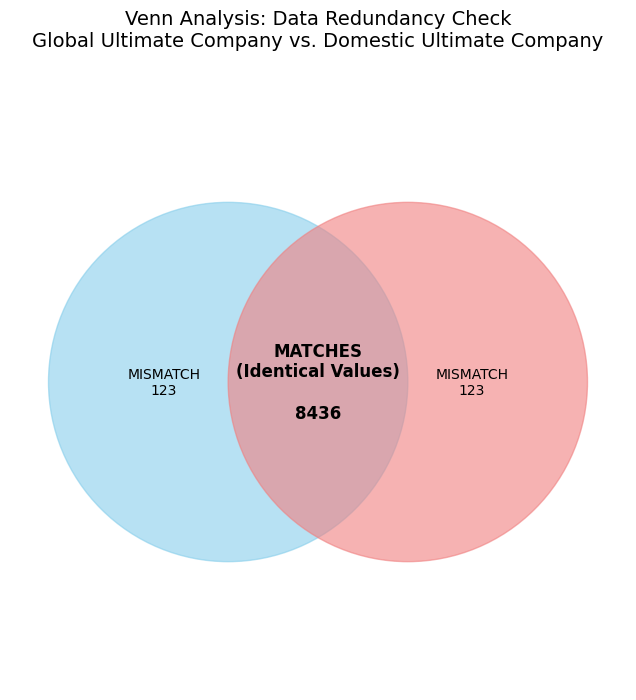

Analysis Complete: 8436 companies have identical values for both columns.


In [ ]:
# 1. Create a list of columns to drop
# Keep "DUNS Number " for now, to verify different companies
cols_to_drop = ["8-Digit SIC Code", "8-Digit SIC Description",
    "Phone Number", "NAICS Description", "NACE Rev 2 Description",
    "Lattitude", "Longitude", "ANZSIC Description",
    "Address Line 1", "State", "State Or Province Abbreviation",
    "Postal Code", "Country", "Region",
    "Ownership Type", "Employees Single Site", "SIC Description",
    "Parent Street Address", "Parent State/Province", "Parent State/Province Abbreviation",
    "Parent Postal Code", "Parent Country/Region", "Global Ultimate Street Address",
    "Global Ultimate State/Province", "ISIC Rev 4 Description",
    "Ultimate State/Province Abbreviation", "Global Ultimate Postal Code",
    "Domestic Ultimate Street Address", "Company Description",
    "Domestic Ultimate State/Province Name", "Domestic Ultimate State Abbreviation",
    "Domestic Ultimate Postal Code", "Registration Number",
    "Company Status (Active/Inactive)", "Fiscal Year End"
]

# 2. Create a copy of the dataframe and drop the columns
# .copy() ensures the original 'data' remains untouched
data_dropped = data_cleaned.drop(columns=cols_to_drop).copy()

# 3. Verify the remaining columns
print(data_dropped.info())

# Matches between 'Global Ultimate Company' and 'Domestic Ultimate Company'
# 1. Calculate the components for the Venn Diagram
# Number of rows where both columns have the same value
matches = (data['Global Ultimate Company'] == data['Domestic Ultimate Company']).sum()

# Number of rows where they are different
mismatches = (data['Global Ultimate Company'] != data['Domestic Ultimate Company']).sum()

# Optional: Number of rows where data is missing in one but not the other
# (Assuming for this visual that both columns are mostly populated)

# 2. Create the Visual
fig, ax = plt.subplots(figsize=(8, 8))

# Draw two overlapping circles
circle_left = plt.Circle((-0.35, 0), 0.7, color='skyblue', alpha=0.6, label='Global Ultimate Company')
circle_right = plt.Circle((0.35, 0), 0.7, color='lightcoral', alpha=0.6, label='Domestic Ultimate Company')

ax.add_patch(circle_left)
ax.add_patch(circle_right)

# Set the plot limits and hide axes
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_aspect('equal')
plt.axis('off')

# 3. Add Text Annotations
# The Overlap (Matches)
plt.text(0, 0, f"MATCHES\n(Identical Values)\n\n{matches}",
         ha='center', va='center', fontsize=12, fontweight='bold')

# The Left Side (Discrepancies/Multi-site)
plt.text(-0.6, 0, f"MISMATCH\n{mismatches}",
         ha='center', va='center', fontsize=10)

# The Right Side (Usually same as left in a column-to-column comparison)
plt.text(0.6, 0, f"MISMATCH\n{mismatches}",
         ha='center', va='center', fontsize=10)

plt.title("Venn Analysis: Data Redundancy Check\nGlobal Ultimate Company vs. Domestic Ultimate Company", fontsize=14, pad=20)

# Save the plot
plt.savefig('employees_venn_analysis.png', bbox_inches='tight')
plt.show()

print(f"Analysis Complete: {matches} companies have identical values for both columns.")

# matches = (data['Global Ultimate Company'] == data['Domestic Ultimate Company']).sum()

# print(f"Number of rows where both columns match: {matches}")

## 2. Data Cleaning and Exploratory Checks
In the next few steps, we will perform initial data quality and exploratory checks, including:


1. Check for duplicate records
2. Identify and handle missing values.
3. Detect outliers in numerical features.
4. Review features for potential data leakage.
5. Examine class imbalance in the variables. (Include potential transformed variables)

## 2A: Determining duplicates or "near-duplicates" then removing them

We first check for any repeat of exact matches of where there are none. Then we check for "near-duplicates" based of key variables like having the same 'Company Sites', 'City', 'Year Found' but not the same value for any of the other variables.

We discovered that the only company that has this 'near-duplicate' is Zhoukou Construction Engineering Co., Ltd., there are 2 entries under this same name although both have a different DUNS number. We chose to remove the "Zhoukou Construction Engineering Co., Ltd." with a smaller Revenue as we suspect although they are separate legal entities, it is likely that they are operating under the same operators.

In [ ]:
# data['Company Sites'].value_counts()

# 1. Check how many exact duplicates exist
exact_duplicates = data_dropped.duplicated().sum()
print(f"Number of exact duplicate rows: {exact_duplicates}")

# 1. Sort by a "Completeness" metric (Revenue or IT Spend)
# This ensures that if there's a duplicate, we keep the record with the most data
data_dropped = data_dropped.sort_values(by='Revenue (USD)', ascending=False)

# 2. Identify duplicates based on the Entity Name
# We use 'Company Sites' as the unique identifier
# We add 'City' and 'Year Found' as a secondary check to distinguish between  genuine branches and true data duplicates.
duplicate_subset = ['Company Sites', 'City', 'Year Found']

# 3. Drop and Reset
data_dropped = data_dropped.drop_duplicates(subset=duplicate_subset, keep='first').reset_index(drop=True)

print(f"De-duplication complete based on Company Sites.")
print(f"Remaining records: {len(data_dropped)}, vs original {len(data)}")

# 1. Identify the 'Company Sites' names from the ORIGINAL data
target_names = data[data['DUNS Number '].isin([547949213, 547808179])]['Company Sites'].unique()

# 2. Check if those names exist in your NEW cleaned dataframe
presence_check = data_dropped[data_dropped['Company Sites'].isin(target_names)]

print(f"Entities found in data_dropped: {len(presence_check)}")
print(presence_check[['Company Sites', 'Employees Total', 'Revenue (USD)']])

Number of exact duplicate rows: 0
De-duplication complete based on Company Sites.
Remaining records: 8558, vs original 8559
Entities found in data_dropped: 1
                                         Company Sites  Employees Total  \
239  Zhoukou Construction Engineering Co., Ltd.    ...             1680   

     Revenue (USD)  
239       18854550  


## 2B: Investigating Missingness and how to handle each case

We first check which columns/variables have missing data  then we use a phi correlation heatmap to measure nullity correlation which helps to determine the type of missingness. This gives us insight into how we should handle the different types of missingness.

**Missing NOT at Random (MNAR)**:`NACE Rev 2 Code`, `Is Headquarters`, `Is Domestic Ultimate`, `ANZSIC Code`, `ISIC Rev 4 Code` all these variables show near-perfect associations ($\phi = 0.96$ to $1.00$). We also have the outlier of `NAICS Code` which has a substantially lower correlation ($\phi \approx 0.52 \text{--} 0.56$).

However, using domain knowledge we know that the Industry Codes (NAICS, ANZSIC, ISIC, NACE), they are nominal categorical variables represented by numeric values with meaning. Hence, we will create a master industry column, and use the SIC code to fill in the blanks for the missing industries.

However, for `Is Headquarters` and `Is Domestic Ultimate`, we will convert it into a Binary Flag (1 = Present, 0 = Not Linked/Standalone). The matrix shows these identify a specific "type" of corporate entry that standalone sites simply do not have.
So (0, 0) = Standalone, (1, 1) = Top-level entities, (0, 1) = Domestic Ultimates only.


**MNAR**: Variables, `No. of Storage Devices`, `No. of Servers`, `No. of Routers`, these variables have a high association between Servers and Storage ($0.93$). We note that they have a negative correlation ($\approx -0.29$) with corporate hierarchy features. This suggests that "missing" in this group highly correlates with being a smaller or standalone entity. Hence, we will use Constant Imputation (0) as a new category.

**MNAR**: Variables: `Ticker`, `Registration Number Type`, `Manufacturing Status`, `Franchise Status`.

`Franchise Status` and `Ticker` show low correlation with other groups, indicating their missingness is tied to their specific business nature (e.g., Private vs. Public). Based on previous analysis in section 1C, we know that the percentage of Private companies with missing Tickers is 100.00% which makes sense since only publicly listed companies will have a Ticker value. Hence we simply flag missing values as 0 = "private".

While for `Franchise Status` we turn it into a binary flag variable, converting "FALSE" to 0 and "TRUE" = 1, filling in null values as 0.

Additionally, we have the `Registration Number Type` and `Manufacturing Status`, from previous analysis we know that all the non-null values are the same and have 0 variance. Furthermore, now with the missingness analysis, we will turn them into binary flag variables (with 0 = unknown and 1 = Yes) with the flag variables being called `Is_Indonesia_Legalization_Registered` and `Is_Manufacturing_Firm`, respectively.


**Missing at Random (MAR)**:

**MAR (Structural)**: Variables: `Parents City`, `Global Ultimate City Name`, `Domestic Ultimate City Name`, these variables have perfect association ($0.99$ to $1.00$) between the Ultimate City names. We evaluated this based on the given data dictionary which says "Blank if not linked. So missingness here isn't an error, it tells us the company is a standalone entity with no parent. Hence, we simply impute the original columns with a null values to a placeholder 'Standalone". There is no need to create a new boolean variable `Single entity` (1 = True, 0 = False) since `Entity Type` already covers this.

**MAR**: Variables: `No. of PC`, `No. of Desktops`, `No. of Laptops`, these variables have strong internal associations ($0.65$ to $0.90$). They are ordinal categorical variables since they are binned ranges,we can use the known hardware counts to predict the missing ones using MICE (Multiple Imputation by Chained Equations).

**Missing Completely at Random (MCAR)**: Variables: `Website`, `Year Found`, `Legal Status`, `City`.  These show very low $\phi$ associations (near $0.00$) with almost all other variables.. For **Website** since it represents a url and is a string, we cannot use normal imputation methods. Hence we will simply convert it into a binary flag for digital presence. While for **Year Found**, we will use Median Imputation to avoid "batch" bias.


Additionally, `Legal Status` is likely to be a numerically encoded nominal categorical variable. So we should use a specific numeric flag like -1 or 99 (and document it as "Unknown/Not Linked"). This prevents the model from treating it as a continuous number while resolving the null.

References:
1. https://www.naics.com/naics-code-description/
2. https://ec.europa.eu/eurostat/documents/3859598/5902521/KS-RA-07-015-EN.PDF.pdf/dd5443f5-b886-40e4-920d-9df03590ff91?t=1414781457000
3. https://www.abs.gov.au/statistics/classifications/australian-and-new-zealand-standard-industrial-classification-anzsic/2006-revision-2-0/numbering-system-and-titles
4. https://unstats.un.org/unsd/publication/seriesm/seriesm_4rev4e.pdf







                             Missing Count  Percentage (%)
Ticker                                8554       99.953260
Registration Number Type              8550       99.906520
Manufacturing Status                  8297       96.950222
Website                               7933       92.696892
ANZSIC Code                           7132       83.337228
Is Headquarters                       7091       82.858144
Is Domestic Ultimate                  7044       82.308951
NACE Rev 2 Code                       7044       82.308951
ISIC Rev 4 Code                       7044       82.308951
Franchise Status                      6037       70.542183
NAICS Code                            5386       62.935265
No. of Storage Devices                3433       40.114513
No. of Servers                        3349       39.132975
No. of Routers                        3299       38.548726
Year Found                             774        9.044169
No. of Laptops                         639        7.4666

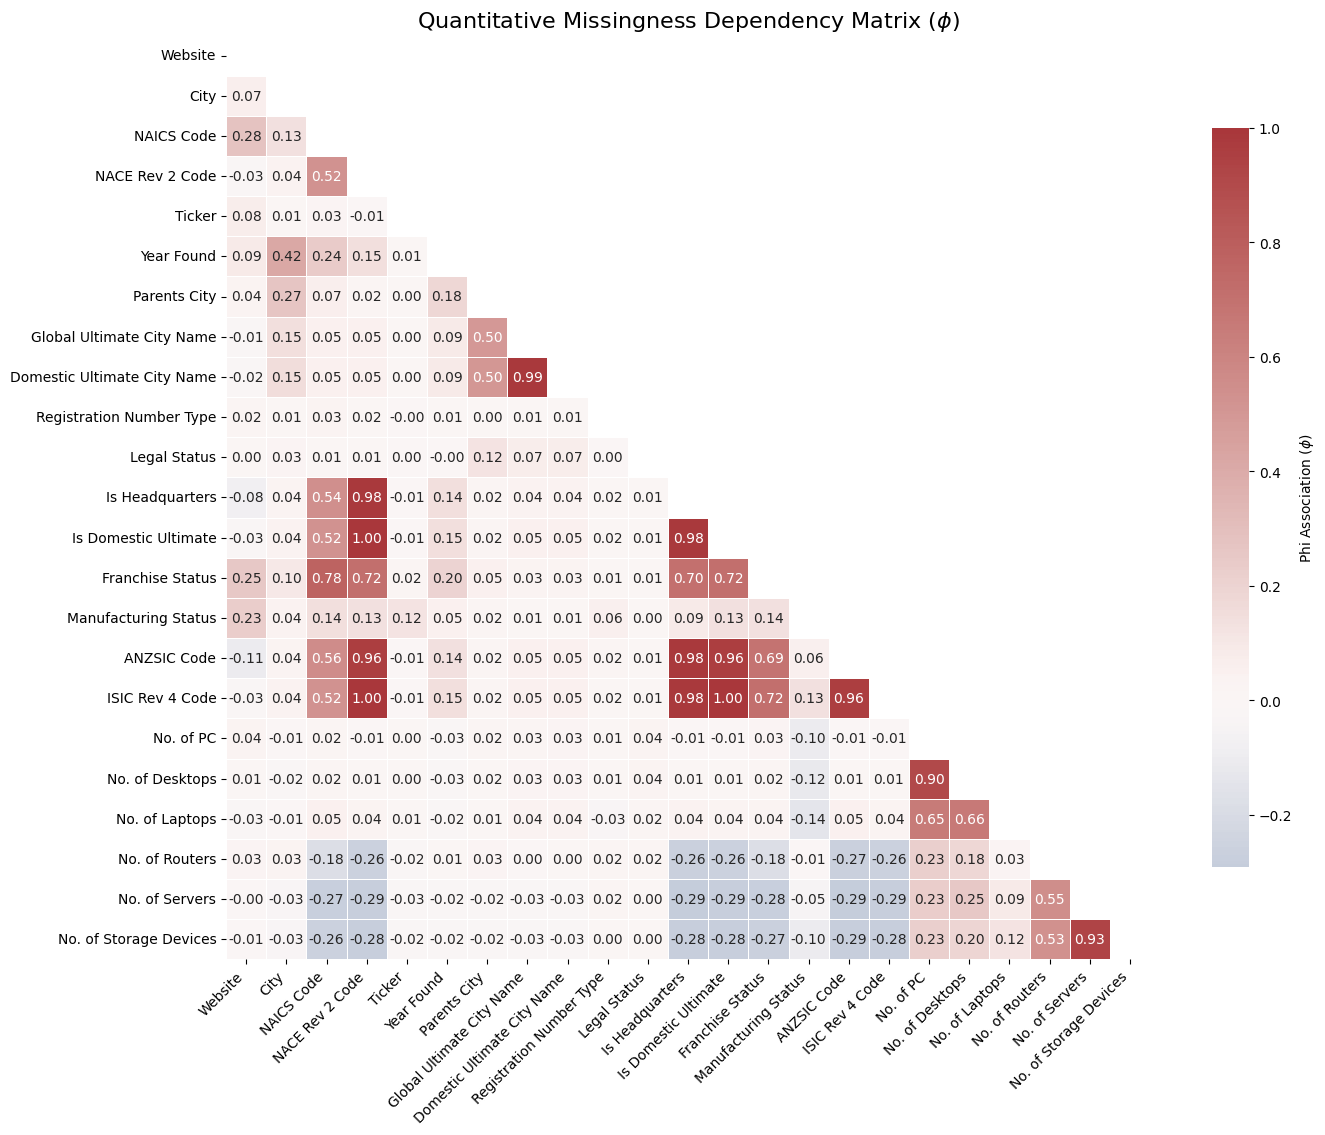

Is_Headquarters_Flag  Is_Domestic_Ultimate_Flag
0                     0                            7044
1                     1                            1467
0                     1                              47
Name: count, dtype: int64
Missing values after 0-imputation:
No. of Storage Devices    0
No. of Servers            0
No. of Routers            0
dtype: int64

Distribution of Server Counts (including imputed zeros):
No. of Servers
1 to 10        5202
0              3349
51 to 200         6
501 to 1000       1
Name: count, dtype: int64
Franchise Status Counts (0=No, 1=Yes):
Is_Confirmed_Not_Franchise
0    8558
Name: count, dtype: int64

Specific Information Flags:
Is_Indonesia_Legalization_Registered      8
Is_Manufacturing_Firm                   261
dtype: int64
Geography Imputation Summary:
                          Parents City       Global Ultimate City Name  \
count                             8558                            8558   
unique                             47

In [ ]:
# 1. Calculate the number of missing values per column
missing_count = data_dropped.isnull().sum()

# 2. Calculate the percentage of missingness
missing_percentage = (data_dropped.isnull().sum() / len(data_dropped)) * 100

# 3. Combine into a summary table for easy viewing
missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Percentage (%)': missing_percentage
}).sort_values(by='Percentage (%)', ascending=False)

# Display only columns that have at least one missing value
print(missing_summary[missing_summary['Missing Count'] > 0])

# 1. Create binary missingness matrix (1 = Missing, 0 = Present)
M = data_dropped.isna().astype(int)

# 2. Filter for columns that actually have missing data
cols_with_missing = M.columns[M.sum() > 0]
n = len(cols_with_missing)
phi_matrix = pd.DataFrame(np.zeros((n, n)), index=cols_with_missing, columns=cols_with_missing)

# 3. Calculate Pairwise Phi (MCC)
for i in range(n):
    for j in range(n):
        col_i = cols_with_missing[i]
        col_j = cols_with_missing[j]
        # MCC is the same as Phi for binary data
        phi_matrix.loc[col_i, col_j] = matthews_corrcoef(M[col_i], M[col_j])

# 4. Visualization
plt.figure(figsize=(16, 12))

# Mask the diagonal (self-correlation is always 1.0)
mask = np.triu(np.ones_like(phi_matrix, dtype=bool))

# Plot the heatmap
sns.heatmap(phi_matrix,
            annot=True,
            fmt=".2f",
            cmap="vlag", # Better for showing positive/negative correlations
            center=0,
            mask=mask,
            square=True,
            linewidths=.5,
            cbar_kws={"shrink": .8, 'label': 'Phi Association ($\phi$)'})

plt.title("Quantitative Missingness Dependency Matrix ($\phi$)", fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.show()

# Handling missingness by cases

data_fill_in_missing = data_dropped.copy()

# Industry codes (NAICS, ANZSIC, ISIC, NACE)

def get_master_industry(row):
    # Helper to safely clean and pad codes to 4 digits
    def pad_code(val):
        if pd.isna(val): return None
        # Convert to string, remove '.0' if it's a float, then pad to 4 digits
        return str(int(float(val))).zfill(4)

    # Priority 1 & 2: Modern Codes

    # 1. NAICS Check (First 2 digits)
    naics = pad_code(row.get('NAICS Code'))
    if naics:
        val = int(naics[:2])
        if val == 11: return "Agriculture, Forestry, Fishing and Hunting"
        if val == 21: return "Mining"
        if val == 22: return "Utilities"
        if val == 23: return "Construction"
        if 31 <= val <= 33: return "Manufacturing"
        if val == 42: return "Wholesale Trade"
        if 44 <= val <= 45: return "Retail Trade"
        if 48 <= val <= 49: return "Transportation and Warehousing"
        if val == 51: return "Information"
        if val == 52: return "Finance and Insurance"
        if val == 53: return "Real Estate Rental and Leasing"
        if val == 54: return "Professional, Scientific, and Technical Services"
        if val == 55: return "Management of Companies and Enterprises"
        if val == 56: return "Administrative and Support and Waste Services"
        if val == 61: return "Educational Services"
        if val == 62: return "Health Care and Social Assistance"
        if val == 71: return "Arts, Entertainment, and Recreation"
        if val == 72: return "Accommodation and Food Services"
        if val == 81: return "Other Services (except Public Administration)"
        if val == 92: return "Public Administration"

    # 2. NACE Rev 2 Check (Standardized 2-digit prefix)
    nace = pad_code(row.get('NACE Rev 2 Code'))
    if nace:
        val = int(nace[:2])
        if 1 <= val <= 3: return "Agriculture, forestry, and fishing"
        if 5 <= val <= 9: return "Mining and quarrying"
        if 10 <= val <= 33: return "Manufacturing"
        if val == 35: return "Electricity, gas, steam, and air conditioning supply"
        if 36 <= val <= 39: return "Water supply; sewerage, waste management"
        if 41 <= val <= 43: return "Construction"
        if 45 <= val <= 47: return "Wholesale and retail trade"
        if 49 <= val <= 53: return "Transportation and storage"
        if 55 <= val <= 56: return "Accommodation and food service activities"
        if 58 <= val <= 63: return "Information and communication"
        if 64 <= val <= 66: return "Financial and insurance activities"
        if val == 68: return "Real estate activities"
        if 69 <= val <= 75: return "Professional, scientific, and technical activities"
        if 77 <= val <= 82: return "Administrative and support service activities"
        if val == 84: return "Public administration and defence"
        if val == 85: return "Education"
        if 86 <= val <= 88: return "Human health and social work activities"
        if 90 <= val <= 93: return "Arts, entertainment, and recreation"
        if 94 <= val <= 96: return "Other service activities"

    # 3. ISIC Rev 4 Check (Correctly handles '31' as '03' via padding)
    isic = pad_code(row.get('ISIC Rev 4 Code'))
    if isic:
        val = int(isic[:2])
        if 1 <= val <= 3: return "Agriculture, forestry and fishing"
        if 5 <= val <= 9: return "Mining and quarrying"
        if 10 <= val <= 33: return "Manufacturing"
        if val == 35: return "Electricity, gas, steam and air conditioning supply"
        if 36 <= val <= 39: return "Water supply; sewerage, waste management"
        if 41 <= val <= 43: return "Construction"
        if 45 <= val <= 47: return "Wholesale and retail trade"
        if 49 <= val <= 53: return "Transportation and storage"
        if 55 <= val <= 56: return "Accommodation and food service activities"
        if 58 <= val <= 63: return "Information and communication"
        if 64 <= val <= 66: return "Financial and insurance activities"
        if val == 68: return "Real estate activities"
        if 69 <= val <= 75: return "Professional, scientific and technical activities"
        if 77 <= val <= 82: return "Administrative and support service activities"
        if val == 84: return "Public administration and defence"
        if val == 85: return "Education"
        if 86 <= val <= 88: return "Human health and social work activities"
        if 90 <= val <= 93: return "Arts, entertainment and recreation"
        if 94 <= val <= 96: return "Other service activities"

    # 4. ANZSIC Code Check
    anzsic = pad_code(row.get('ANZSIC Code'))
    if anzsic:
        val = int(anzsic) # Whole 4 digits used for ANZSIC ranges
        if 100 <= val <= 599: return "Agriculture, Forestry and Fishing"
        if 600 <= val <= 1099: return "Mining"
        if 1100 <= val <= 2599: return "Manufacturing"
        if 2600 <= val <= 2999: return "Electricity, Gas, Water and Waste Services"
        if 3000 <= val <= 3299: return "Construction"
        if 3300 <= val <= 3899: return "Wholesale Trade"
        if 3900 <= val <= 4399: return "Retail Trade"
        if 4400 <= val <= 4599: return "Accommodation and Food Services"
        if 4600 <= val <= 5399: return "Transport, Postal and Warehousing"
        if 5400 <= val <= 6099: return "Information Media and Telecommunications"
        if 6200 <= val <= 6499: return "Financial and Insurance Services"
        if 6600 <= val <= 6799: return "Rental, Hiring and Real Estate Services"
        if 6900 <= val <= 7099: return "Professional, Scientific and Technical Services"
        if 7200 <= val <= 7399: return "Administrative and Support Services"
        if 7500 <= val <= 7799: return "Public Administration and Safety"
        if 8000 <= val <= 8299: return "Education and Training"
        if 8400 <= val <= 8799: return "Health Care and Social Assistance"
        if 8900 <= val <= 9299: return "Arts and Recreation Services"
        if 9400 <= val <= 9699: return "Other Services"

    # Fallback: SIC Code
    if pd.notna(row.get('SIC Code')):
        sic = int(row['SIC Code'])
        if 100 <= sic <= 999: return "Agriculture, Forestry, Fishing"
        elif 1000 <= sic <= 1499: return "Mining"
        elif 1500 <= sic <= 1799: return "Construction"
        elif 2000 <= sic <= 3999: return "Manufacturing"
        elif 4000 <= sic <= 4999: return "Transportation, Communications, Utilities"
        elif 5000 <= sic <= 5199: return "Wholesale Trade"
        elif 5200 <= sic <= 5999: return "Retail Trade"
        elif 6000 <= sic <= 6799: return "Finance, Insurance, Real Estate"
        elif 7000 <= sic <= 8999: return "Services"
        elif 9100 <= sic <= 9729: return "Public Administration"
        elif 9900 <= sic <= 9999: return "Nonclassifiable"

    return "Unknown"

# Run the classification
data_fill_in_missing["Master Industry"] = data_fill_in_missing.apply(get_master_industry, axis=1)
data_fill_in_missing.drop(columns=["ANZSIC Code", "NACE Rev 2 Code", "ISIC Rev 4 Code", "NAICS Code", "SIC Code"], inplace=True)

# data_fill_in_missing.info()
data_fill_in_missing['Master Industry'].value_counts()

# List of hierarchy indicators identified in the MNAR block
hierarchy_flags = ["Is Headquarters", "Is Domestic Ultimate"]

for col in hierarchy_flags:
    # 1. We create the binary flag:
    # If the value exists (Present), it becomes 1.
    # If the value is NaN (Not Linked/Standalone), it becomes 0.
    data_fill_in_missing[col] = data_fill_in_missing[col].notna().astype(int)

# Optional: Rename columns to reflect they are now binary flags
data_fill_in_missing = data_fill_in_missing.rename(columns={
    "Is Headquarters": "Is_Headquarters_Flag",
    "Is Domestic Ultimate": "Is_Domestic_Ultimate_Flag"
})

# Verify the transformation
print(data_fill_in_missing[["Is_Headquarters_Flag", "Is_Domestic_Ultimate_Flag"]].value_counts())

# List of hardware infrastructure variables from the MNAR block
infrastructure_cols = ["No. of Storage Devices", "No. of Servers", "No. of Routers"]

# Apply Constant Imputation (0)
# This treats 'Missing' as a functional 'Zero' for standalone/small entities
data_fill_in_missing[infrastructure_cols] = data_fill_in_missing[infrastructure_cols].fillna(0)

# Verify that there are no remaining NaNs in these columns
print("Missing values after 0-imputation:")
print(data_fill_in_missing[infrastructure_cols].isna().sum())

# Display the distribution to see the new '0' category
print("\nDistribution of Server Counts (including imputed zeros):")
print(data_fill_in_missing["No. of Servers"].value_counts().head())

# 1. Ticker: Numeric Placeholder (0) for Private companies
# Keeps the column continuous/numeric for the model
data_fill_in_missing["Ticker"] = pd.to_numeric(data_fill_in_missing["Ticker"], errors='coerce').fillna(0)

# 2. Registration Number Type: Information-Rich Flag
# Rename to capture that 'Present' means 'Indonesia Legalization Number'
data_fill_in_missing["Is_Indonesia_Legalization_Registered"] = data_fill_in_missing["Registration Number Type"].notna().astype(int)
data_fill_in_missing.drop(columns=["Registration Number Type"], inplace=True)

# 3. Franchise Status: Binary Numeric conversion
# Create the Flag: '1' if the status was recorded as 'FALSE' (Confirmed Not a Franchise)
# '0' if the status was NaN (Unknown/Not Recorded)
data_fill_in_missing["Is_Confirmed_Not_Franchise"] = (data_fill_in_missing["Franchise Status"] == 'FALSE').astype(int)

# 2. Drop the original column
data_fill_in_missing.drop(columns=["Franchise Status"], inplace=True)

# 4. Manufacturing Status: Information-Rich Flag
# Rename to capture that 'Present' means 'Yes'
data_fill_in_missing["Is_Manufacturing_Firm"] = data_fill_in_missing["Manufacturing Status"].notna().astype(int)
data_fill_in_missing.drop(columns=["Manufacturing Status"], inplace=True)

# Verify the transformations
print("Franchise Status Counts (0=No, 1=Yes):")
print(data_fill_in_missing["Is_Confirmed_Not_Franchise"].value_counts())

print("\nSpecific Information Flags:")
print(data_fill_in_missing[["Is_Indonesia_Legalization_Registered", "Is_Manufacturing_Firm"]].sum())

# List of geography columns identified as perfectly associated (phi 0.99 - 1.00)
geography_cols = ["Parents City", "Global Ultimate City Name", "Domestic Ultimate City Name"]

# Apply the placeholder 'Standalone' to all null values in these columns
for col in geography_cols:
    data_fill_in_missing[col] = data_fill_in_missing[col].fillna("Standalone")

# Verify the transformation
print("Geography Imputation Summary:")
print(data_fill_in_missing[geography_cols].describe())

# Check a sample of rows that were previously NaN
print("\nSample of imputed geography data:")
print(data_fill_in_missing[geography_cols].head())

# Hardware columns
# 1. Define specific mappings for each variable to handle differing bin granularities
pc_map = {
    "1 to 10": 1, "11 to 50": 2, "51 to 100": 3, "101 to 500": 4, "501 to 1000": 5
}

# Desktops and Laptops share the same bins in your value_counts
laptop_desktop_map = {
    "1 to 10": 1, "51 to 200": 3.5, "201 to 500": 4.5
}

# 2. Apply mapping
data_fill_in_missing["No. of PC"] = data_fill_in_missing["No. of PC"].map(pc_map)
data_fill_in_missing["No. of Desktops"] = data_fill_in_missing["No. of Desktops"].map(laptop_desktop_map)
data_fill_in_missing["No. of Laptops"] = data_fill_in_missing["No. of Laptops"].map(laptop_desktop_map)

# 3. Initialize MICE Imputer
# We use 'median' because these are ordinal representations of ranges
mice_imputer = IterativeImputer(random_state=42, max_iter=10, initial_strategy='median')

# 4. Perform Imputation
# We include all three to leverage their internal correlation (0.65 - 0.90)
hardware_cols = ["No. of PC", "No. of Desktops", "No. of Laptops"]
imputed_data = mice_imputer.fit_transform(data_fill_in_missing[hardware_cols])

# 5. Round and clip values to stay within our logical 1-5 rank range
imputed_data = np.clip(np.round(imputed_data, 1), 1, 5)
data_fill_in_missing[hardware_cols] = imputed_data

print("Imputation Complete. Numeric ordinal ranks assigned.")
print(data_fill_in_missing[hardware_cols].head())

print("Imputed Value Distributions:")
for col in ["No. of PC", "No. of Desktops", "No. of Laptops"]:
    print(f"\n{col} distribution:")
    print(data_fill_in_missing[col].value_counts())

# 1. Website: Convert to Binary Flag for 'Digital Presence'
# 1 = Website URL is present, 0 = Missing (Unknown digital presence)
data_fill_in_missing['Digital_Presence_Flag'] = data_fill_in_missing['Website'].notna().astype(int)

# 2. Year Found: Median Imputation
# Using median protects against "batch bias" from specific data collection years
median_year = data_fill_in_missing['Year Found'].median()
data_fill_in_missing['Year Found'] = data_fill_in_missing['Year Found'].fillna(median_year)

# 3. Legal Status: Numeric Placeholder
# Using -1 ensures the model can treat 'Unknown' as a distinct nominal category
# without implying a mathematical relationship to other status codes
data_fill_in_missing['Legal Status'] = data_fill_in_missing['Legal Status'].fillna(-1)

# 4. City: Simple Placeholder
# Since City has low correlation, we fill with 'Unknown' to maintain categorical type
data_fill_in_missing['City'] = data_fill_in_missing['City'].fillna('Unknown')

# Drop the original 'Website' string column as the flag now represents the useful signal
data_fill_in_missing.drop(columns=['Website'], inplace=True)

# Verification: Final check for any remaining nulls in the entire dataframe
print("Remaining Null Values in Dataset:")
print(data_fill_in_missing.isna().sum().sum())

# Drop DUNS Number, no longer needed
data_fill_in_missing = data_fill_in_missing.drop(columns="DUNS Number ")

# Address missingness
# Variables identified in the structural cluster (distance < 15)
# hierarchy_cols = ['Parents City', 'Global Ultimate City Name', 'Domestic Ultimate City Name']

# Impute with 'Standalone' to resolve the MAR missingness without creating redundant flags
# data_dropped[hierarchy_cols] = data_dropped[hierarchy_cols].fillna('Standalone')

# 2C Outlier detection and removal

We first separate the variables into their respective types, quantitative (discrete, continuous), categorical (ordinal, nominal) and binary variables.
Variables types:

# **Quantitative**

**Discrete (7)**: `Employees Total`, `Revenue (USD)`, `Corporate Family Members`, `Market Value (USD)`, `IT Budget`, `IT spend`, `Year Found`

Considerations:

**The "Zero-Placeholder" Effect**: Since we used 0 as a placeholder for Ticker (Private companies) and other hardware variables, the IQR calculation for those specific columns might result in an IQR of 0 if the majority of the data is 0. If this happens, every non-zero value (e.g., every public company) would be flagged as an outlier.

**Business Anomalies**: Remember that in firmographics, the largest companies (by Revenue or Employees) are often statistically "outliers" but are valid business entities. Removing them during cleaning ensures your KNN model focuses on the "majority" market behavior. To fix this, we separate out the outliers into a anomalous dataframe which we will merge back into the final dataframe after running the grouping algorithm.


**Continuous (1)**: `Ticker`


# **Categorical**

**Ordinal (6)**: `No. of PC`, `No. of Desktops`, `No. of Laptops`, `No. of Routers`, `No. of Servers`, `No. of Storage Devices`


**Nominal (12)**: `Company Sites`, `City`, `Entity Type`, `Parent Company`, `Parents City`, `Global Ultimate Company`, `Global Ultimate City Name`, `Global Ultimate Country Name`, `Domestic Ultimate Company`, `Domestic Ultimate City Name`, `Legal Status`, `Master Industry`


**Binary (6)**: `Is_Headquarters_Flag`, `Is_Domestic_Ultimate_Flag`, `Is_Indonesia_Legalization_Registered`, `Is_Confirmed_Not_Franchise`, `Is_Manufacturing_Firm`, `Digital_Presence_Flag`



# **Overall strategy:**
1. Tag & Separate:
2. For quantitative variables we identify the 3.0 $\times$ IQR companies and move them to an anomalies_df. Note that we use 3.0 instead of the standard IQR calculation of 1.5 because it is well known that financial data involving business is heavily skewed, mimicking the power laws hence there is a need to be extend the range.
(https://www.aeaweb.org/articles?id=10.1257/jep.30.1.185 and
https://www.sciencedirect.com/science/article/abs/pii/S2352673423000768).
3. For categorical variables, we exclude binary flag variables because of the way we imputed the missing values. Then we only choose selected variables excluding those with high uniqueness like names or if they conflicted with our cleaning methods. Those selected are: `City`, `Entity Type`, `Master Industry`,`Parents City`, `Global Ultimate City Name`, `Domestic Ultimate City Name` (Note for the cities names, they had a missing percentage of < 5% for all categories hence our imputation method is less impactful on the result).
4. Lastly, we check for outliers in our newly created column `Outlier_Count` and remove rows with the outlier value and keep them in the separate dataframe anomalies_df.
5. Group the Majority: Run our grouping algorithm (KNN or ...) on the data_outlier_cleaned to find subtle patterns (e.g., distinguishing "High-Tech SMEs" from "Traditional SMEs").
6. Perform Cross-Analysis: Lastly, examine the anomalies_df and check if the outliers firms follow the same logic as our algorithm separated groups, or are they a unique business risk?"


In [ ]:
# 0. PRE-PROCESSING: NUMERIC MAPPING FOR HARDWARE
# We must convert strings to numbers so .quantile() can perform sorting math
router_map = {"0": 0, "1 to 10": 1, "11 to 50": 2, "51 to 100": 3, "101 to 500": 4}
server_map = {"0": 0, "1 to 10": 1, "51 to 200": 3.5, "501 to 1000": 5}
storage_map = {"0": 0, "1 to 10": 1, "51 to 200": 3.5, "201 to 500": 4.5, "501 to 1000": 5}

# Apply mappings (assuming these are the columns causing the TypeError)
# Note: Ensure No. of PC, Laptops, and Desktops are already numeric from your previous steps
data_fill_in_missing['No. of Routers'] = data_fill_in_missing['No. of Routers'].astype(str).replace(router_map)
data_fill_in_missing['No. of Servers'] = data_fill_in_missing['No. of Servers'].astype(str).replace(server_map)
data_fill_in_missing['No. of Storage Devices'] = data_fill_in_missing['No. of Storage Devices'].astype(str).replace(storage_map)

# START OF MAIN OUTLIER LOGIC
data_fill_in_missing['Outlier_Count'] = 0

# 1. QUANTITATIVE TAGGING (3.0x IQR / Outer Fences)
quantitative_cols = [
    "Employees Total", "Revenue (USD)", "Corporate Family Members",
    "Market Value (USD)", "IT Budget", "IT spend", "Year Found", "Ticker"
]

for col in quantitative_cols:
    if col in data_fill_in_missing.columns:
        # Ensure data is numeric
        data_fill_in_missing[col] = pd.to_numeric(data_fill_in_missing[col], errors='coerce').fillna(0)

        Q1 = data_fill_in_missing[col].quantile(0.25)
        Q3 = data_fill_in_missing[col].quantile(0.75)
        IQR = Q3 - Q1

        if IQR > 0:
            upper_bound = Q3 + 3.0 * IQR
            data_fill_in_missing.loc[data_fill_in_missing[col] > upper_bound, 'Outlier_Count'] += 1

# 2. CATEGORICAL TAGGING (Rare Levels & High Infrastructure)
hardware_cols = [
    "No. of PC", "No. of Desktops", "No. of Laptops",
    "No. of Routers", "No. of Servers", "No. of Storage Devices"
]

for col in hardware_cols:
    if col in data_fill_in_missing.columns:
        # Now that they are numeric, quantile will work perfectly
        upper_threshold = data_fill_in_missing[col].quantile(0.95)
        if upper_threshold > 0:
            data_fill_in_missing.loc[data_fill_in_missing[col] > upper_threshold, 'Outlier_Count'] += 1

# Nominal: Tagging "Rare Nature"
nominal_cols = ["City", "Master Industry", "Entity Type", "Parents City", "Global Ultimate City Name", "Domestic Ultimate City Name"]
rare_threshold = 0.005 * len(data_fill_in_missing)

for col in nominal_cols:
    if col in data_fill_in_missing.columns:
        counts = data_fill_in_missing[col].value_counts()
        rare_levels = counts[counts < rare_threshold].index
        data_fill_in_missing.loc[data_fill_in_missing[col].isin(rare_levels), 'Outlier_Count'] += 1

# 3. EXTREME REMOVAL (3 Standard Deviation Method)
mean_outliers = data_fill_in_missing['Outlier_Count'].mean()
std_outliers = data_fill_in_missing['Outlier_Count'].std()
cutoff = mean_outliers + (2.5 * std_outliers)

is_extreme = data_fill_in_missing['Outlier_Count'] > cutoff
anomalies_df = data_fill_in_missing[is_extreme].copy()
data_outlier_cleaned = data_fill_in_missing[~is_extreme].copy()

# SUMMARY REPORT
print(f"--- Final Multivariate Outlier Strategy ---")
print(f"Calculated 3SD Cutoff Score: {cutoff:.2f}")
print(f"Entities kept in 'Majority' set: {len(data_outlier_cleaned)}")
print(f"Entities moved to 'Anomalies' set: {len(anomalies_df)}")
print(f"\nAverage outlier tags per record: {mean_outliers:.2f}")
print(f"Max tags found on a single record: {data_fill_in_missing['Outlier_Count'].max()}")

--- Final Multivariate Outlier Strategy ---
Calculated 3SD Cutoff Score: 7.19
Entities kept in 'Majority' set: 8388
Entities moved to 'Anomalies' set: 170

Average outlier tags per record: 1.90
Max tags found on a single record: 15


# Data Visualisation

In [ ]:
data_outlier_cleaned.columns

Index(['Company Sites', 'City', 'Entity Type', 'Employees Total',
       'Revenue (USD)', 'Ticker', 'Year Found', 'Parent Company',
       'Parents City', 'Global Ultimate Company', 'Global Ultimate City Name',
       'Global Ultimate Country Name', 'Domestic Ultimate Company',
       'Domestic Ultimate City Name', 'Legal Status',
       'Corporate Family Members', 'Is_Headquarters_Flag',
       'Is_Domestic_Ultimate_Flag', 'Market Value (USD)', 'IT Budget',
       'IT spend', 'No. of PC', 'No. of Desktops', 'No. of Laptops',
       'No. of Routers', 'No. of Servers', 'No. of Storage Devices',
       'Master Industry', 'Is_Indonesia_Legalization_Registered',
       'Is_Confirmed_Not_Franchise', 'Is_Manufacturing_Firm',
       'Digital_Presence_Flag', 'Outlier_Count'],
      dtype='object')

In [ ]:
num_cols = data_outlier_cleaned.select_dtypes(include=["number"]).columns.tolist()


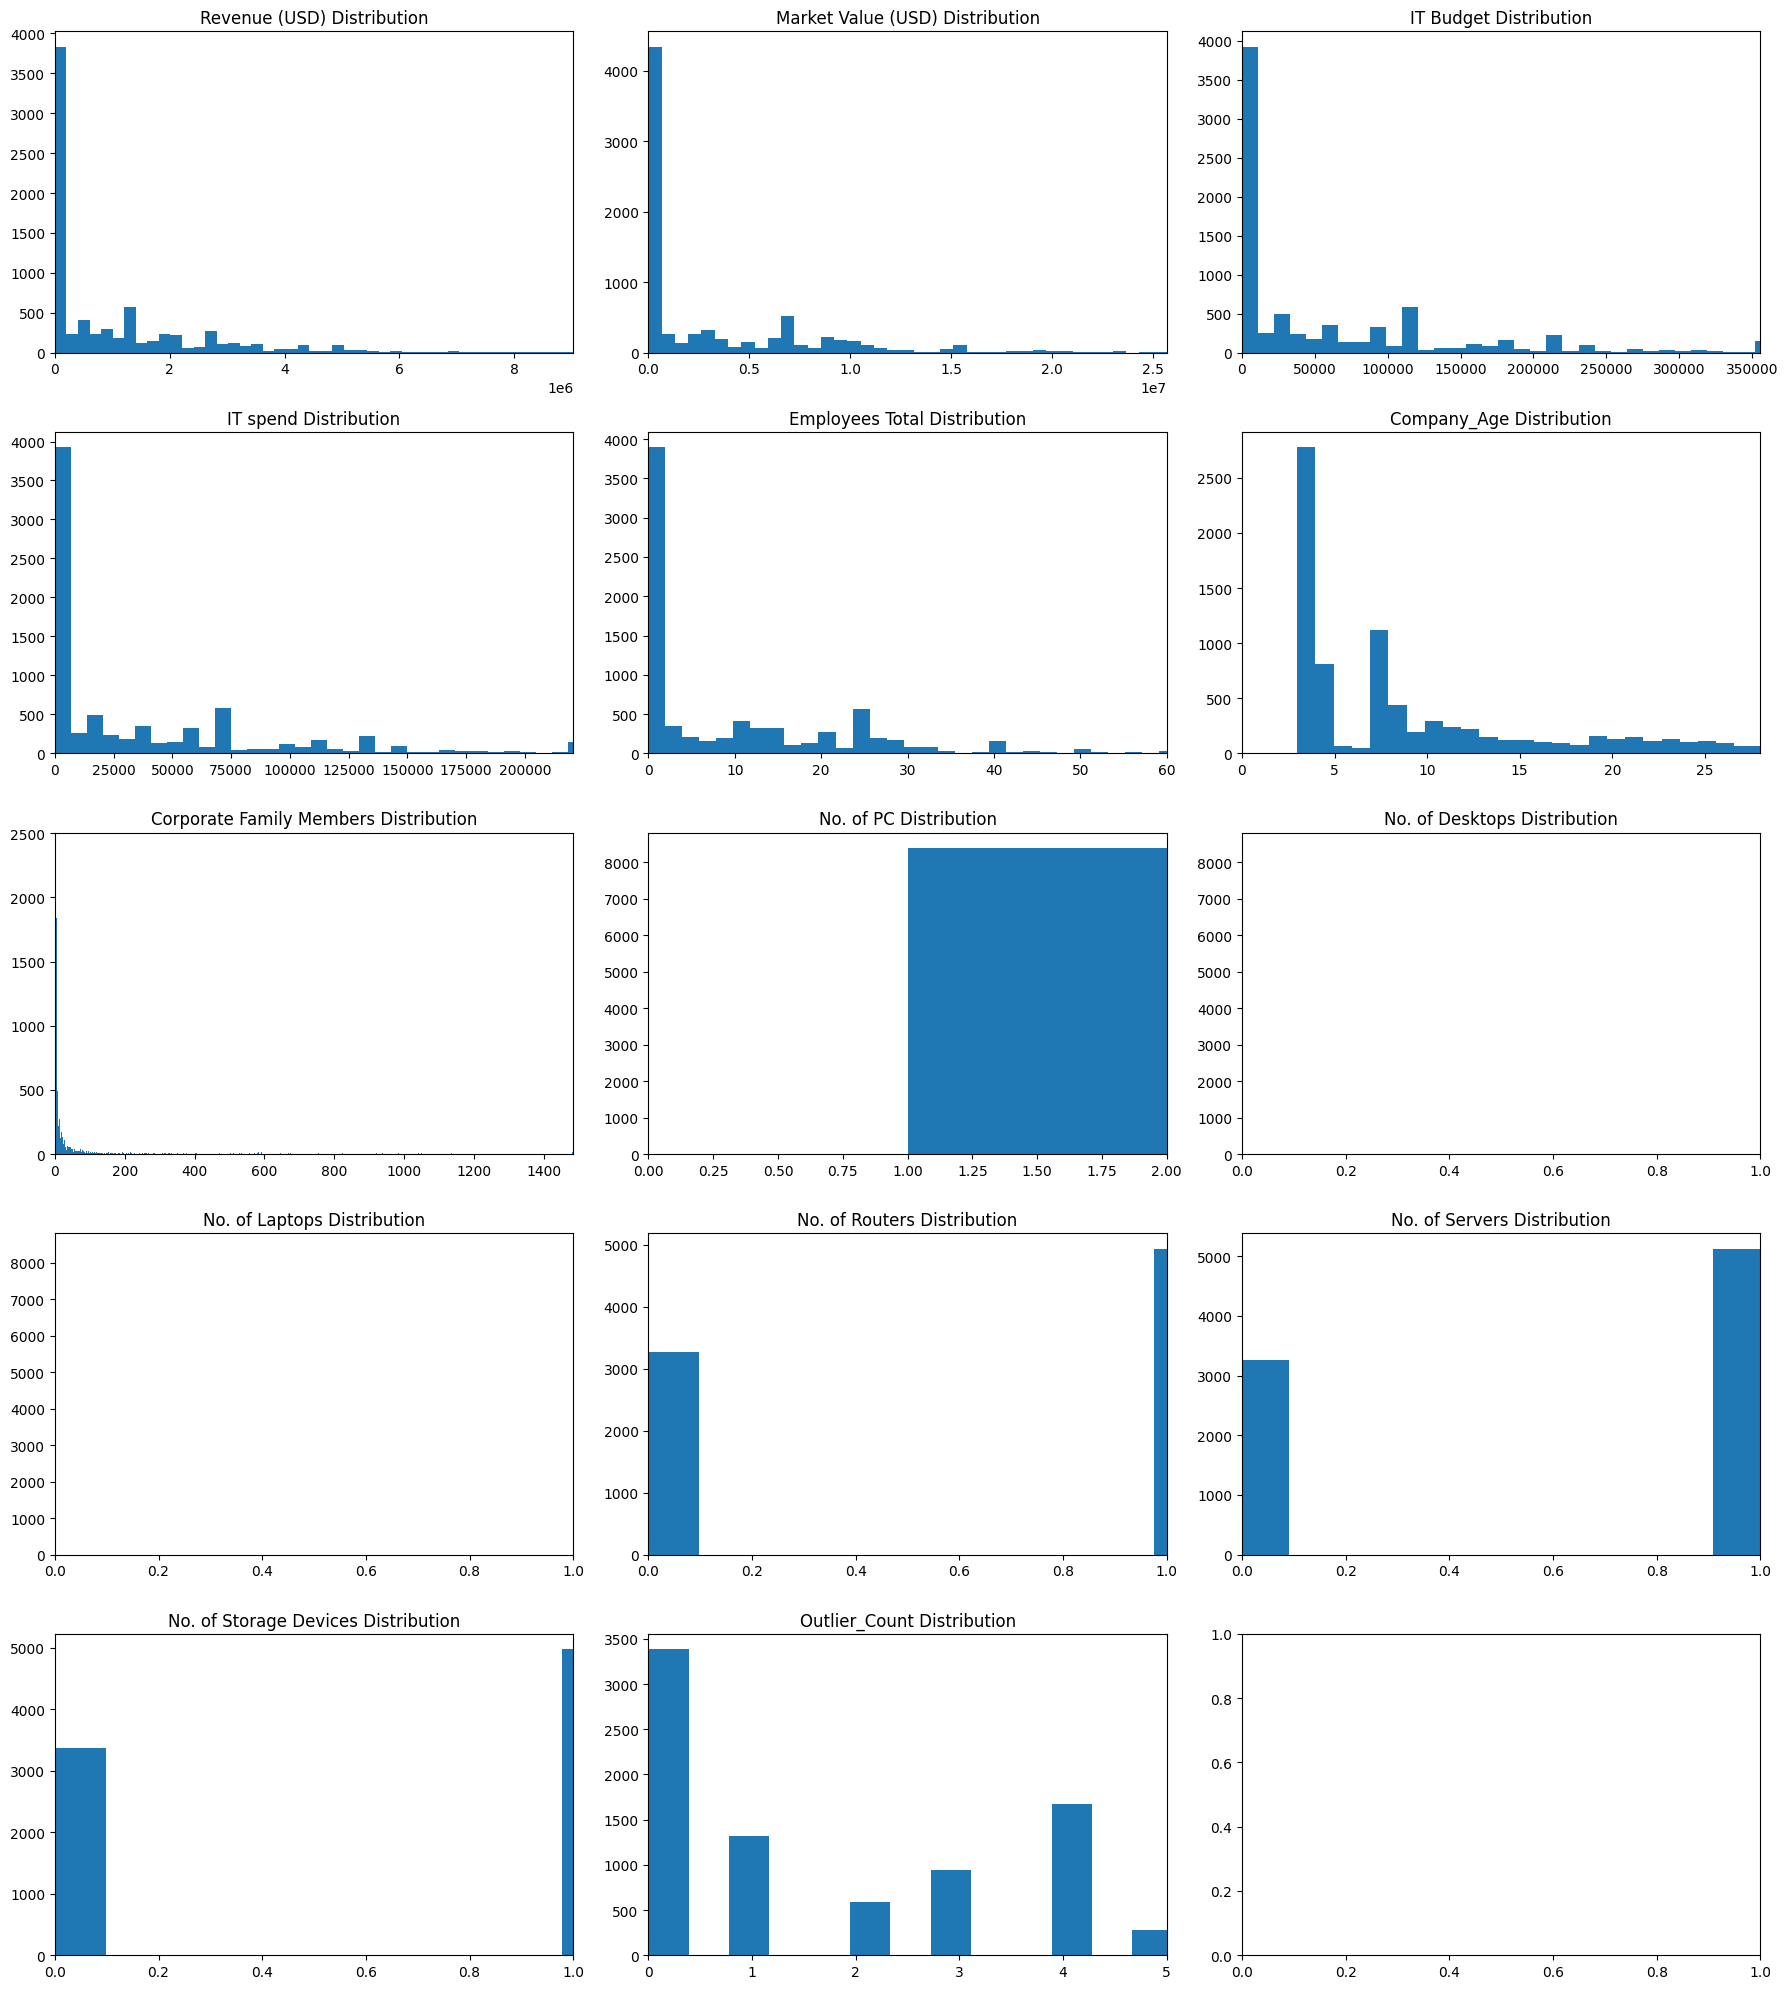

In [ ]:
data_outlier_cleaned['Company_Age']=pd.Timestamp.now().year - data_outlier_cleaned['Year Found'] # Use Company Age Instead of Year Found for easier interpretation
num_cols=[
    "Revenue (USD)",
    "Market Value (USD)",
    "IT Budget",
    "IT spend",
    "Employees Total",
    "Company_Age",
    "Corporate Family Members",
    "No. of PC",
    "No. of Desktops",
    "No. of Laptops",
    "No. of Routers",
    "No. of Servers",
    "No. of Storage Devices",
    "Outlier_Count"
]
num_cols = [c for c in num_cols if c in data_outlier_cleaned.columns]

n = len(num_cols)
ncols = 3
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 4*nrows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    data_outlier_cleaned[col].hist(bins="fd", ax=axes[i], grid=False)
    axes[i].set_title(f"{col} Distribution")
    s = data_outlier_cleaned[col]
    hi = np.percentile(s, 95)
    axes[i].set_xlim(0, hi)


plt.tight_layout()
plt.show()

In [ ]:
data_outlier_cleaned['Company_Age']=pd.Timestamp.now().year - data_outlier_cleaned['Year Found']

In [ ]:
num_cols=[
    "Revenue (USD)",
    "Market Value (USD)",
    "IT Budget",
    "IT spend",
    "Employees Total",
    "Company_Age",
    "Corporate Family Members",
    "No. of PC",
    "No. of Desktops",
    "No. of Laptops",
    "No. of Routers",
    "No. of Servers",
    "No. of Storage Devices",
    "Outlier_Count"
]

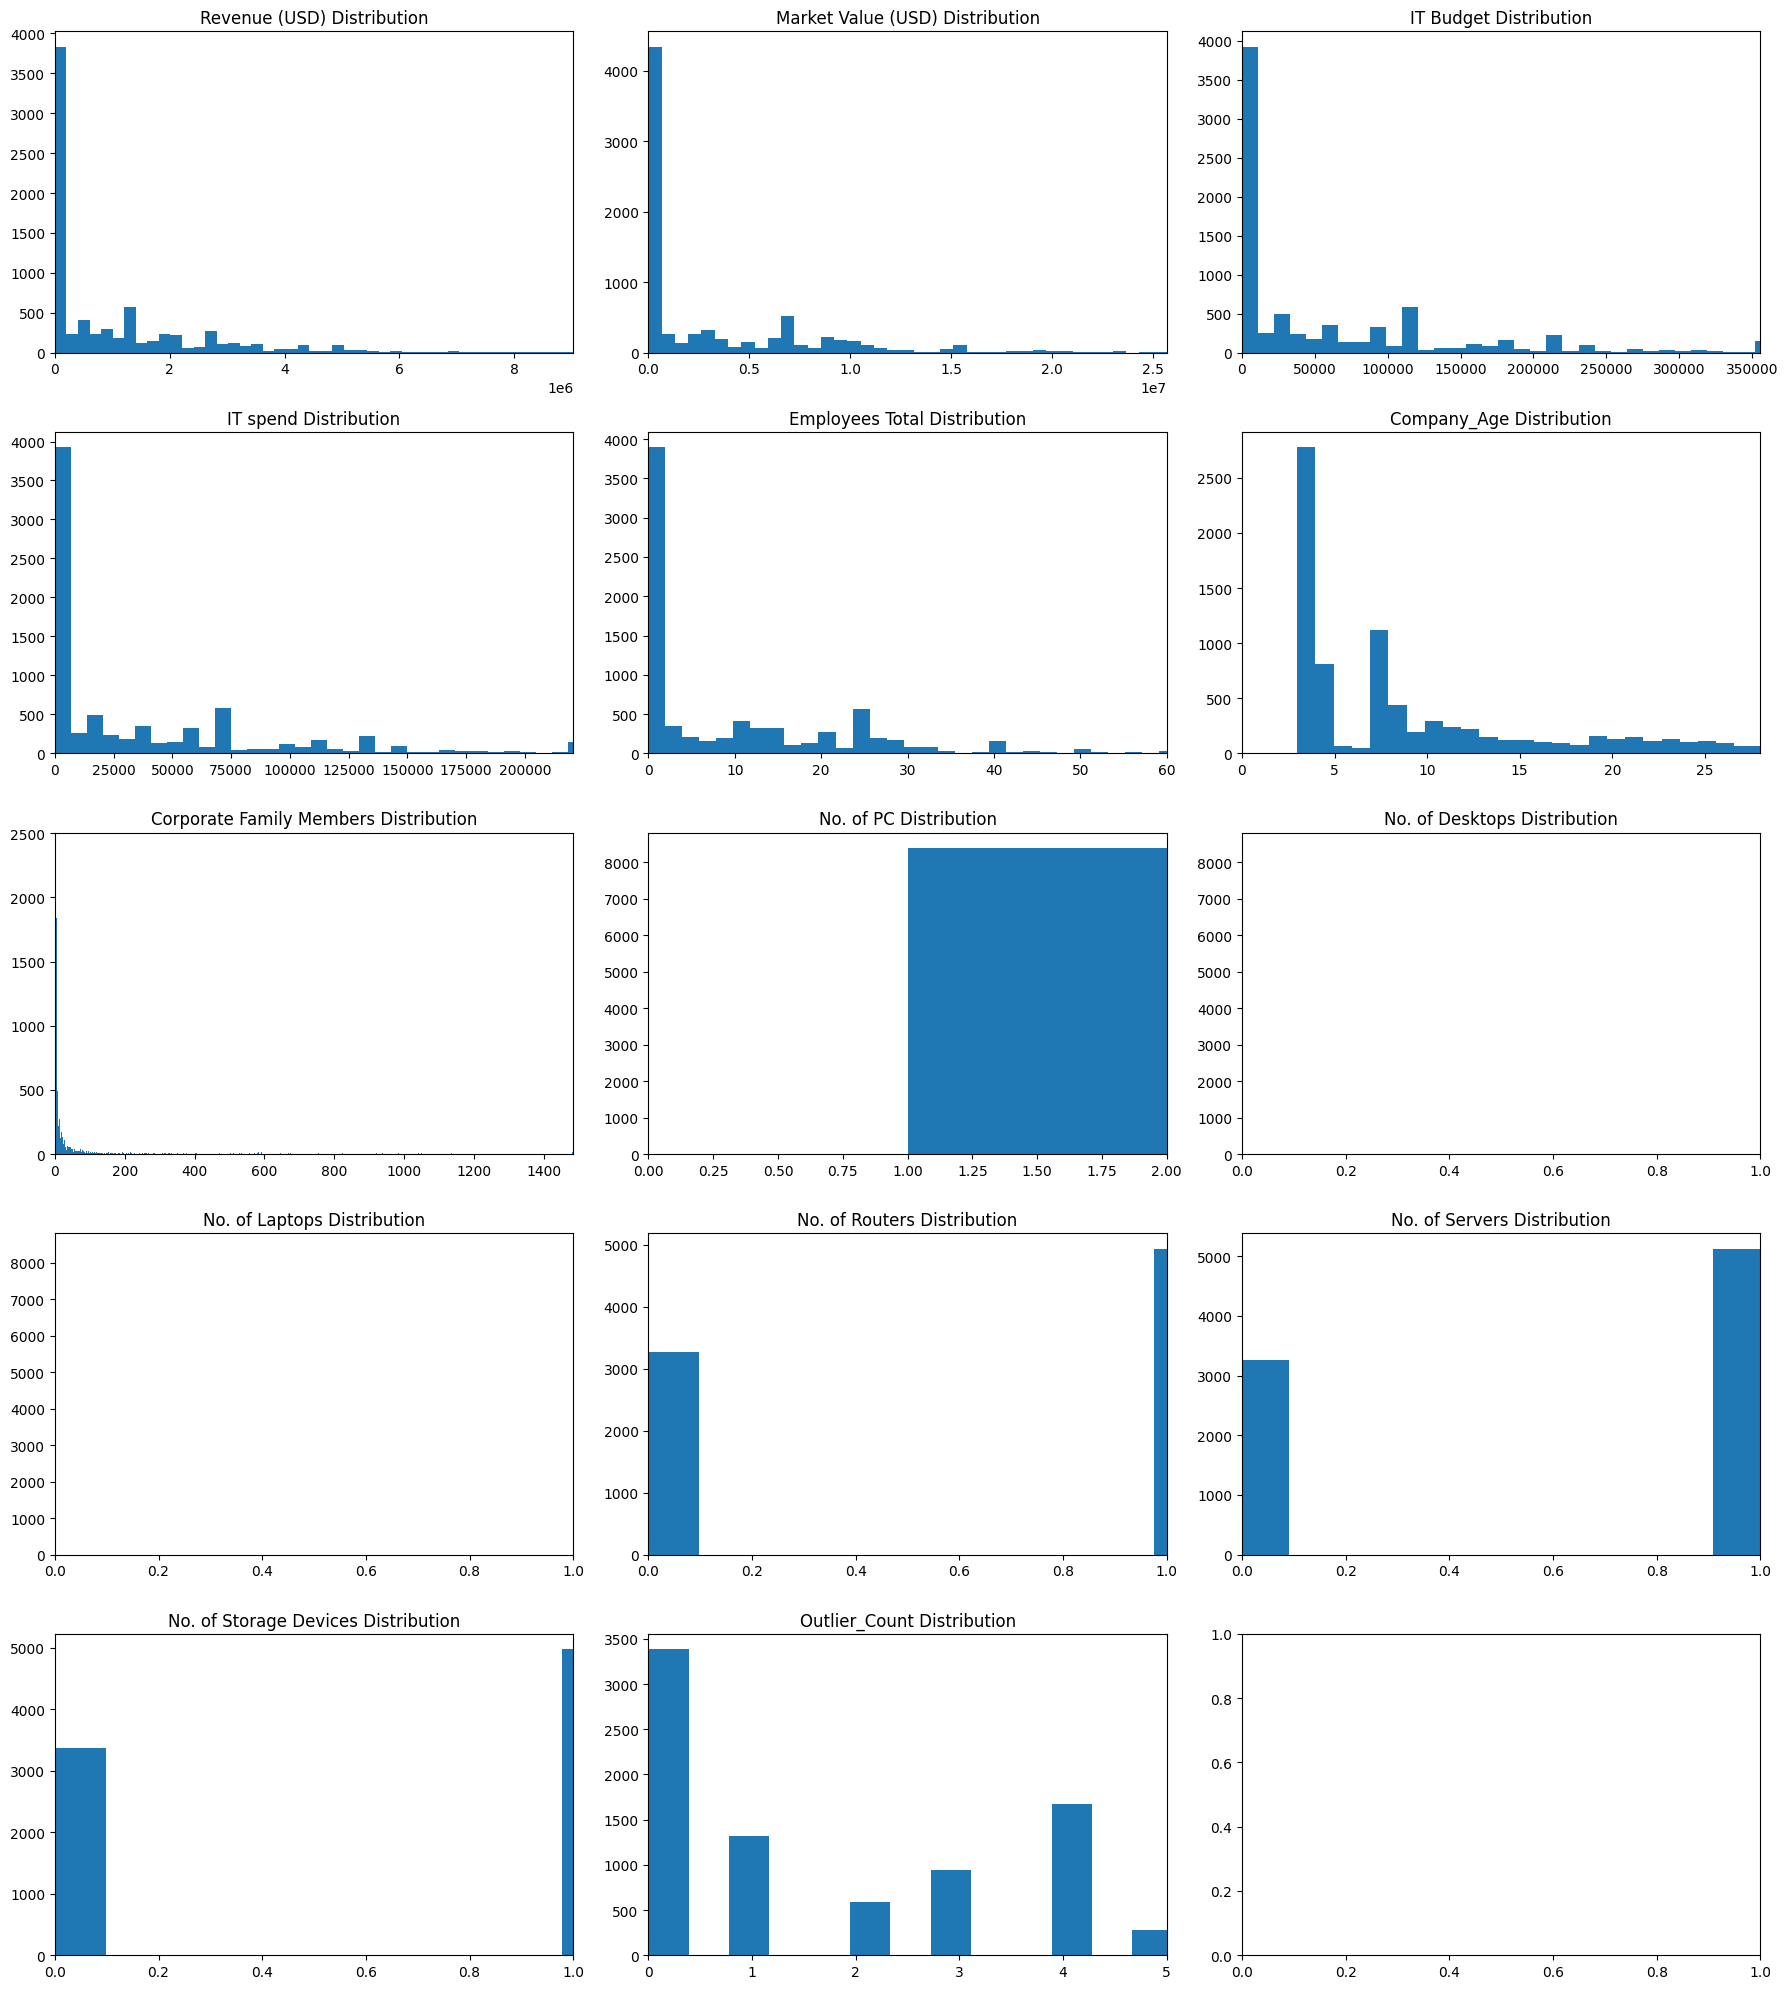

In [ ]:
num_cols = [c for c in num_cols if c in data_outlier_cleaned.columns]

n = len(num_cols)
ncols = 3
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 4*nrows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    data_outlier_cleaned[col].hist(bins="fd", ax=axes[i], grid=False)
    axes[i].set_title(f"{col} Distribution")
    s = data_outlier_cleaned[col]
    hi = np.percentile(s, 95)
    axes[i].set_xlim(0, hi)

plt.tight_layout()
plt.show()

In [ ]:
cat_cols = data_outlier_cleaned.select_dtypes(include=["object"]).columns.tolist()

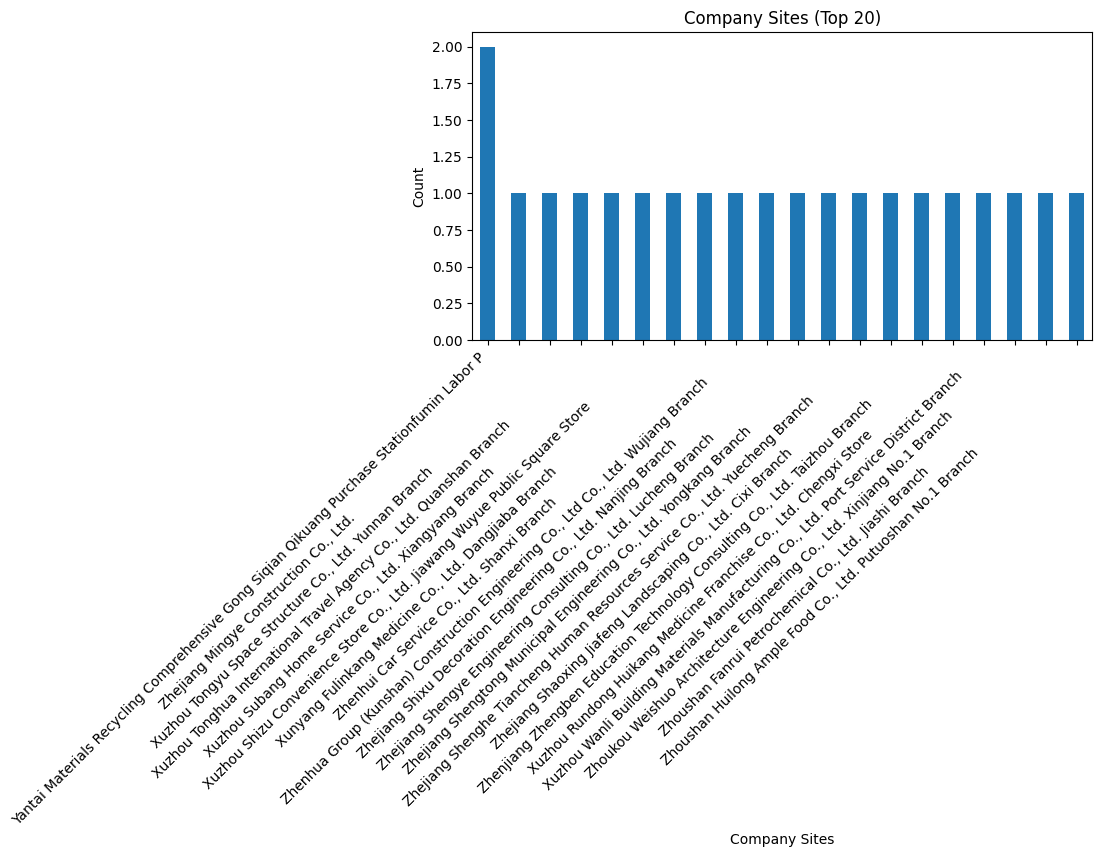

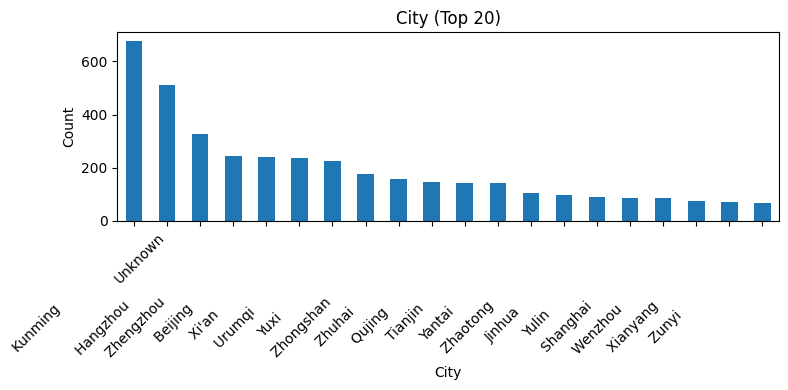

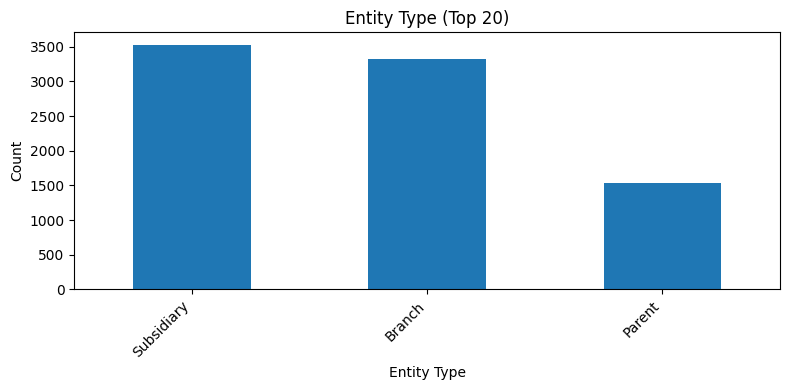

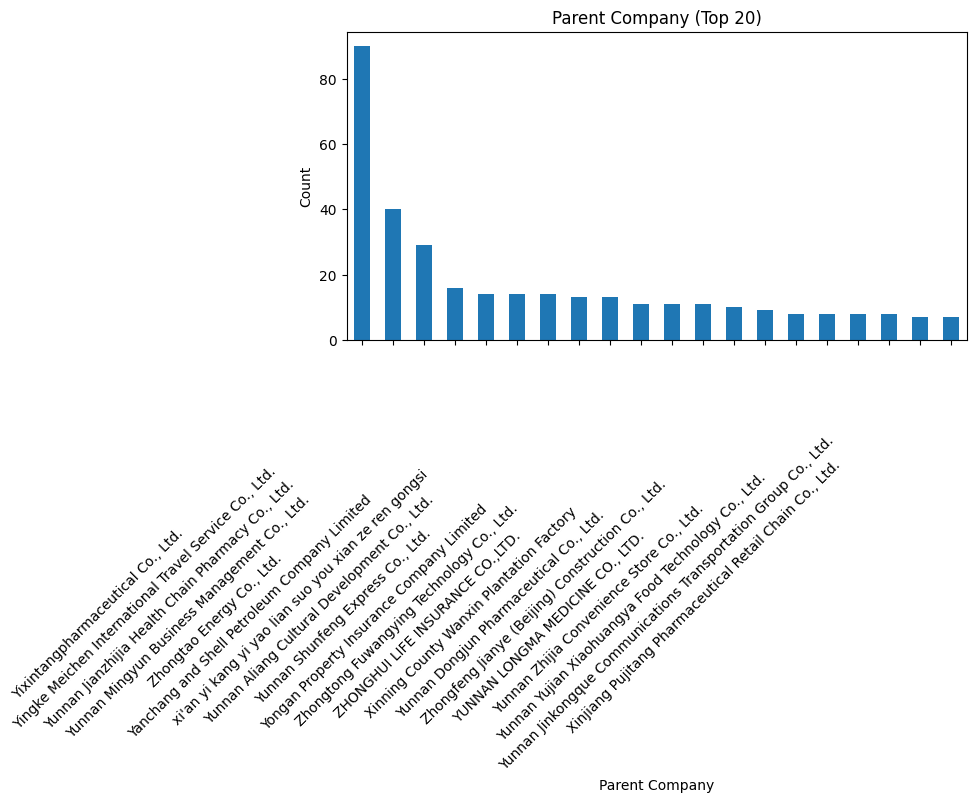

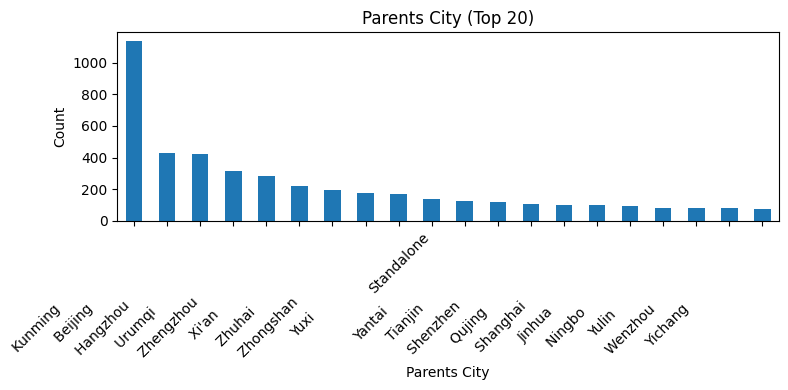

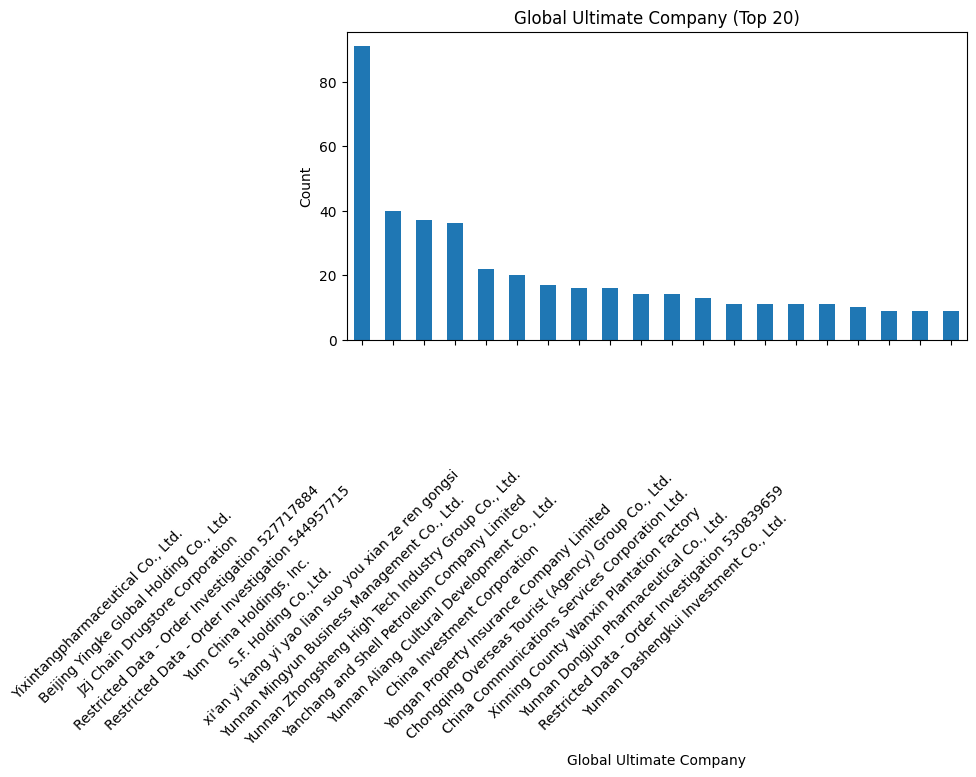

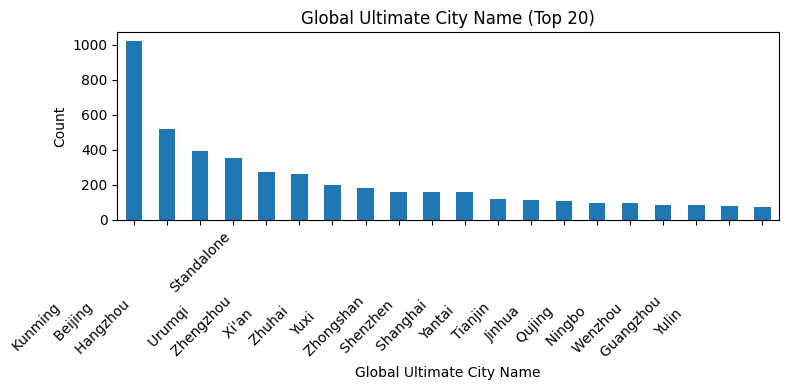

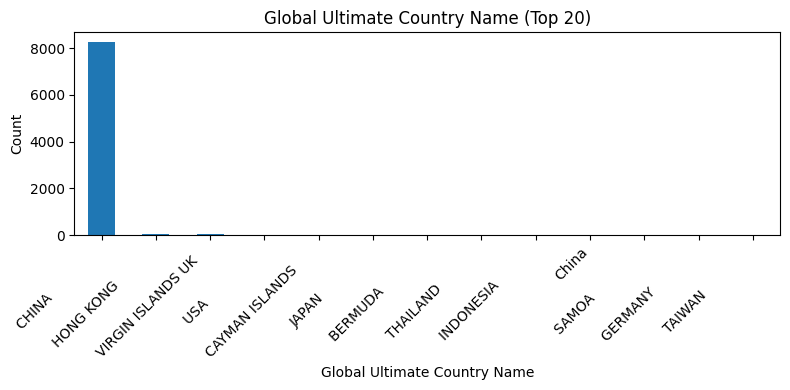

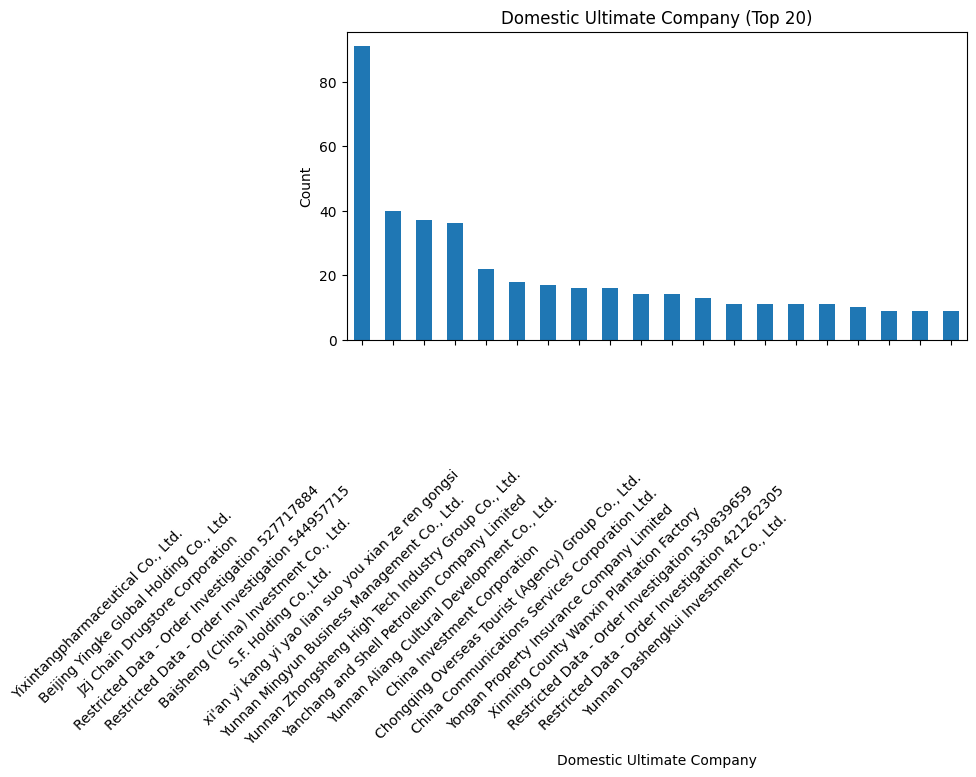

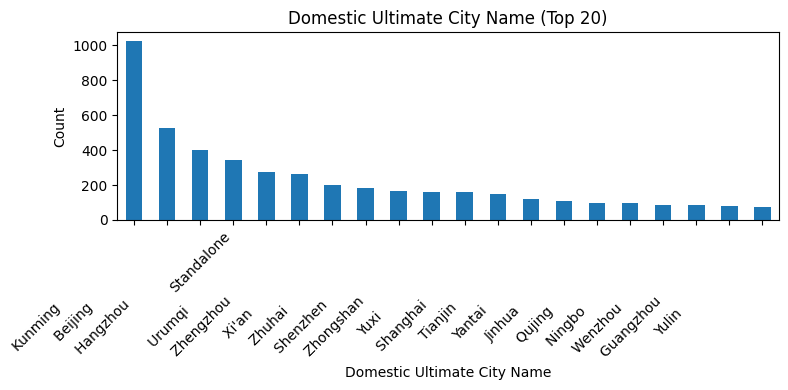

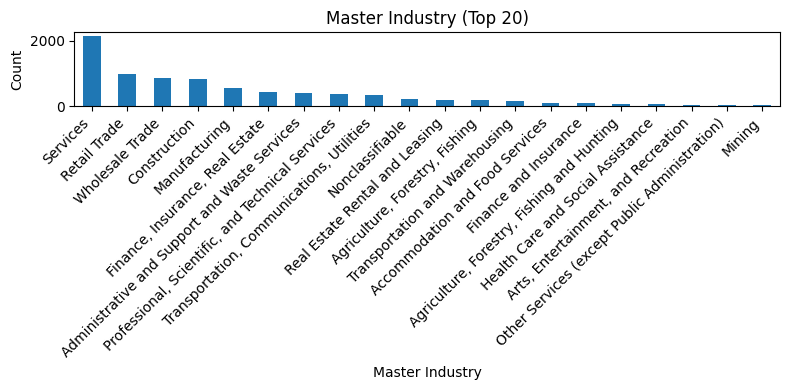

In [ ]:
cat_cols = [c for c in cat_cols if c in data_outlier_cleaned.columns]

for col in cat_cols:
    plt.figure(figsize=(8, 4))
    data_outlier_cleaned[col].fillna("Missing").value_counts().head(20).plot(kind="bar", grid=False)
    plt.title(f"{col} (Top 20)")
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# Data transformation and feature engineering

In [ ]:
data_outlier_cleaned.head()

,Company Sites,City,Entity Type,Employees Total,Revenue (USD),Ticker,Year Found,Parent Company,Parents City,Global Ultimate Company,Global Ultimate City Name,Global Ultimate Country Name,Domestic Ultimate Company,Domestic Ultimate City Name,Legal Status,Corporate Family Members,Is_Headquarters_Flag,Is_Domestic_Ultimate_Flag,Market Value (USD),IT Budget,IT spend,No. of PC,No. of Desktops,No. of Laptops,No. of Routers,No. of Servers,No. of Storage Devices,Master Industry,Is_Indonesia_Legalization_Registered,Is_Confirmed_Not_Franchise,Is_Manufacturing_Firm,Digital_Presence_Flag,Outlier_Count,Company_Age
0,"Zhejiang Mingye Construction Co., Ltd. ...",Hangzhou,Parent,0,2961727200,0.0,2007.0,"Zhejiang Mingye Construction Co., Ltd. ...",Hangzhou,"Zhejiang Mingye Construction Co., Ltd. ...",Hangzhou,CHINA,"Zhejiang Mingye Construction Co., Ltd. ...",Hangzhou,3.0,6,1,1,0,0,0,1.0,1.0,1.0,0,0.0,0.0,Construction,0,0,0,0,1,19.0
1,"Yonfer Agricultural Technology Co., Ltd. ...",Jingmen,Parent,0,2213321609,902.0,1986.0,"Yonfer Agricultural Technology Co., Ltd. ...",Jingmen,"Yonfer Agricultural Technology Co., Ltd. ...",Jingmen,CHINA,"Yonfer Agricultural Technology Co., Ltd. ...",Jingmen,8.0,38,0,0,0,0,0,1.0,1.0,1.0,0,0.0,0.0,Manufacturing,0,0,1,1,5,40.0
2,"Yimen Copper Industry Co., Ltd. ...",Yuxi,Subsidiary,500,984886398,0.0,1995.0,"Yunnan Copper Co., Ltd. ...",Kunming,"Yunnan Copper Co., Ltd. ...",Kunming,CHINA,"Yunnan Copper Co., Ltd. ...",Kunming,3.0,31,0,0,0,27576819,17097627,4.0,1.0,1.0,2,0.0,3.5,Manufacturing,0,0,1,0,7,31.0
3,"Hangzhou Yage'er Property Co., Ltd. ...",Hangzhou,Subsidiary,25,646052913,0.0,2007.0,"Youngor Real Estate Holding Co., Ltd. ...",Ningbo,"Youngor Group Co., Ltd. ...",Ningbo,CHINA,"Youngor Group Co., Ltd. ...",Ningbo,3.0,985,0,0,0,51038180,31643671,2.0,1.0,1.0,1,1.0,1.0,Construction,0,0,0,0,4,19.0
4,"Sinosteel Shipping& Forwarding Co., Ltd. ...",Beijing,Subsidiary,0,518268069,0.0,1994.0,"Zhonggang International Trade Co., Ltd. ...",Beijing,Restricted Data - Order Investigation 54495771...,Standalone,CHINA,Restricted Data - Order Investigation 54495771...,Standalone,3.0,70723,1,1,1300852853,15548042,9639786,1.0,1.0,1.0,0,0.0,0.0,Transportation and storage,0,0,0,1,6,32.0


In [ ]:
def feature_engineering(df: pd.DataFrame) -> pd.DataFrame:
    feature_table = df.copy()

    feature_table['Entity Type'] = feature_table['Entity Type'].astype('category')
    onehot = pd.get_dummies(data=feature_table['Entity Type'], dtype=int)
    feature_table = pd.concat([feature_table, onehot], axis=1)

    feature_table['Is Domestic Ultimate'] = np.where(feature_table['Company Sites'] == feature_table['Domestic Ultimate Company'], 1, 0)
    feature_table['Years in operation'] = 2026 - feature_table['Year Found']
    feature_table['Proportion of IT budget spent'] = feature_table['IT spend'] / (feature_table['IT Budget'] + 1)
    feature_table['IT budget per employee'] = feature_table['IT Budget'] / (feature_table['Employees Total'] + 1) #Added

    feature_table['City is parent city'] = np.where(feature_table['City'] == feature_table['Parents City'], 1, 0)
    feature_table['City is domestic ultimate'] = np.where(feature_table['City'] == feature_table['Domestic Ultimate City Name'], 1, 0)
    feature_table['IT architecture completeness'] = np.where(feature_table['No. of PC'] > 0, 1, 0) + np.where(feature_table['No. of Desktops'] > 0, 1, 0) + np.where(feature_table['No. of Laptops'] > 0, 1, 0) + \
                                                    np.where(feature_table['No. of Routers'] > 0, 1, 0) + np.where(feature_table['No. of Servers'] > 0, 1, 0) + np.where(feature_table['No. of Storage Devices'] > 0, 1, 0)

    feature_table['Revenue per IT dollar'] = feature_table['Revenue (USD)'] / (feature_table['IT Budget'] + 1)
    feature_table['Revenue per employee'] = feature_table['Revenue (USD)'] / (feature_table['Employees Total'] + 1)
    feature_table['Family members per employee'] = feature_table['Corporate Family Members'] / (feature_table['Employees Total'] + 1)
    feature_table['IT spend per employee'] = feature_table['IT spend'] / (feature_table['Employees Total'] + 1)

    feature_table['Laptop to Desktop ratio'] = feature_table['No. of Laptops'] / (feature_table['No. of Desktops'] + 1)
    feature_table['Servers per 100 employees'] = feature_table['No. of Servers'] / ((feature_table['Employees Total'] / 100) + 1)
    feature_table['IT spend as pct of revenue'] = feature_table['IT spend'] / (feature_table['Revenue (USD)'] + 1)


    return feature_table


df = data_outlier_cleaned.copy()
feature_table = feature_engineering(df)
feature_table.head()

,Company Sites,City,Entity Type,Employees Total,Revenue (USD),Ticker,Year Found,Parent Company,Parents City,Global Ultimate Company,Global Ultimate City Name,Global Ultimate Country Name,Domestic Ultimate Company,Domestic Ultimate City Name,Legal Status,Corporate Family Members,Is_Headquarters_Flag,Is_Domestic_Ultimate_Flag,Market Value (USD),IT Budget,IT spend,No. of PC,No. of Desktops,No. of Laptops,No. of Routers,No. of Servers,No. of Storage Devices,Master Industry,Is_Indonesia_Legalization_Registered,Is_Confirmed_Not_Franchise,Is_Manufacturing_Firm,Digital_Presence_Flag,Outlier_Count,Company_Age,Branch,Parent,Subsidiary,Is Domestic Ultimate,Years in operation,Proportion of IT budget spent,IT budget per employee,City is parent city,City is domestic ultimate,IT architecture completeness,Revenue per IT dollar,Revenue per employee,Family members per employee,IT spend per employee,Laptop to Desktop ratio,Servers per 100 employees,IT spend as pct of revenue
0,"Zhejiang Mingye Construction Co., Ltd. ...",Hangzhou,Parent,0,2961727200,0.0,2007.0,"Zhejiang Mingye Construction Co., Ltd. ...",Hangzhou,"Zhejiang Mingye Construction Co., Ltd. ...",Hangzhou,CHINA,"Zhejiang Mingye Construction Co., Ltd. ...",Hangzhou,3.0,6,1,1,0,0,0,1.0,1.0,1.0,0,0.0,0.0,Construction,0,0,0,0,1,19.0,0,1,0,1,19.0,0.00,0.000000e+00,1,1,3,2.961727e+09,2.961727e+09,6.000000,0.000000e+00,0.5,0.0,0.00000
1,"Yonfer Agricultural Technology Co., Ltd. ...",Jingmen,Parent,0,2213321609,902.0,1986.0,"Yonfer Agricultural Technology Co., Ltd. ...",Jingmen,"Yonfer Agricultural Technology Co., Ltd. ...",Jingmen,CHINA,"Yonfer Agricultural Technology Co., Ltd. ...",Jingmen,8.0,38,0,0,0,0,0,1.0,1.0,1.0,0,0.0,0.0,Manufacturing,0,0,1,1,5,40.0,0,1,0,1,40.0,0.00,0.000000e+00,1,1,3,2.213322e+09,2.213322e+09,38.000000,0.000000e+00,0.5,0.0,0.00000
2,"Yimen Copper Industry Co., Ltd. ...",Yuxi,Subsidiary,500,984886398,0.0,1995.0,"Yunnan Copper Co., Ltd. ...",Kunming,"Yunnan Copper Co., Ltd. ...",Kunming,CHINA,"Yunnan Copper Co., Ltd. ...",Kunming,3.0,31,0,0,0,27576819,17097627,4.0,1.0,1.0,2,0.0,3.5,Manufacturing,0,0,1,0,7,31.0,0,0,1,0,31.0,0.62,5.504355e+04,0,0,5,3.571428e+01,1.965841e+06,0.061876,3.412700e+04,0.5,0.0,0.01736
3,"Hangzhou Yage'er Property Co., Ltd. ...",Hangzhou,Subsidiary,25,646052913,0.0,2007.0,"Youngor Real Estate Holding Co., Ltd. ...",Ningbo,"Youngor Group Co., Ltd. ...",Ningbo,CHINA,"Youngor Group Co., Ltd. ...",Ningbo,3.0,985,0,0,0,51038180,31643671,2.0,1.0,1.0,1,1.0,1.0,Construction,0,0,0,0,4,19.0,0,0,1,0,19.0,0.62,1.963007e+06,0,0,6,1.265823e+01,2.484819e+07,37.884615,1.217064e+06,0.5,0.8,0.04898
4,"Sinosteel Shipping& Forwarding Co., Ltd. ...",Beijing,Subsidiary,0,518268069,0.0,1994.0,"Zhonggang International Trade Co., Ltd. ...",Beijing,Restricted Data - Order Investigation 54495771...,Standalone,CHINA,Restricted Data - Order Investigation 54495771...,Standalone,3.0,70723,1,1,1300852853,15548042,9639786,1.0,1.0,1.0,0,0.0,0.0,Transportation and storage,0,0,0,1,6,32.0,0,0,1,0,32.0,0.62,1.554804e+07,1,0,3,3.333333e+01,5.182681e+08,70723.000000,9.639786e+06,0.5,0.0,0.01860


In [ ]:
feature_table.to_csv('Feature Table')

# Hierarchal Clustering with Gower Distance

In [ ]:
Hierarchy_df = feature_table.copy()
Hierarchy_df.columns

Index(['Company Sites', 'City', 'Entity Type', 'Employees Total',
       'Revenue (USD)', 'Ticker', 'Year Found', 'Parent Company',
       'Parents City', 'Global Ultimate Company', 'Global Ultimate City Name',
       'Global Ultimate Country Name', 'Domestic Ultimate Company',
       'Domestic Ultimate City Name', 'Legal Status',
       'Corporate Family Members', 'Is_Headquarters_Flag',
       'Is_Domestic_Ultimate_Flag', 'Market Value (USD)', 'IT Budget',
       'IT spend', 'No. of PC', 'No. of Desktops', 'No. of Laptops',
       'No. of Routers', 'No. of Servers', 'No. of Storage Devices',
       'Master Industry', 'Is_Indonesia_Legalization_Registered',
       'Is_Confirmed_Not_Franchise', 'Is_Manufacturing_Firm',
       'Digital_Presence_Flag', 'Outlier_Count', 'Company_Age', 'Branch',
       'Parent', 'Subsidiary', 'Is Domestic Ultimate', 'Years in operation',
       'Proportion of IT budget spent', 'IT budget per employee',
       'City is parent city', 'City is domestic ultima

In [ ]:
to_drop_fixed = [

    "Company Sites",
    "Parent Company",
    "Global Ultimate Company",
    "Domestic Ultimate Company",
    "Parents City",
    "Global Ultimate City Name",
    "Domestic Ultimate City Name",
    #"Cluster_Labels",
    "Branch", "Parent", "Subsidiary", "Is Domestic Ultimate",
    "Outlier_Count",
    "Ticker",
]
Hierarchy_df_dropped=Hierarchy_df.drop(columns=to_drop_fixed)

In [ ]:
Hierarchy_df_dropped.columns

Index(['City', 'Entity Type', 'Employees Total', 'Revenue (USD)', 'Year Found',
       'Global Ultimate Country Name', 'Legal Status',
       'Corporate Family Members', 'Is_Headquarters_Flag',
       'Is_Domestic_Ultimate_Flag', 'Market Value (USD)', 'IT Budget',
       'IT spend', 'No. of PC', 'No. of Desktops', 'No. of Laptops',
       'No. of Routers', 'No. of Servers', 'No. of Storage Devices',
       'Master Industry', 'Is_Indonesia_Legalization_Registered',
       'Is_Confirmed_Not_Franchise', 'Is_Manufacturing_Firm',
       'Digital_Presence_Flag', 'Company_Age', 'Years in operation',
       'Proportion of IT budget spent', 'IT budget per employee',
       'City is parent city', 'City is domestic ultimate',
       'IT architecture completeness', 'Revenue per IT dollar',
       'Revenue per employee', 'Family members per employee',
       'IT spend per employee', 'Laptop to Desktop ratio',
       'Servers per 100 employees', 'IT spend as pct of revenue'],
      dtype='object')

In [ ]:
Hierarchy_df_dropped.shape

(8388, 38)

In [ ]:
n_sample = 2000  # try 1000~3000 first
X_s = Hierarchy_df_dropped.sample(n=n_sample, random_state=42)

for c in X_s.select_dtypes(include=["category"]).columns:
    X_s[c] = X_s[c].astype("object")

D = gower.gower_matrix(X_s)   # shape (n_sample, n_sample)


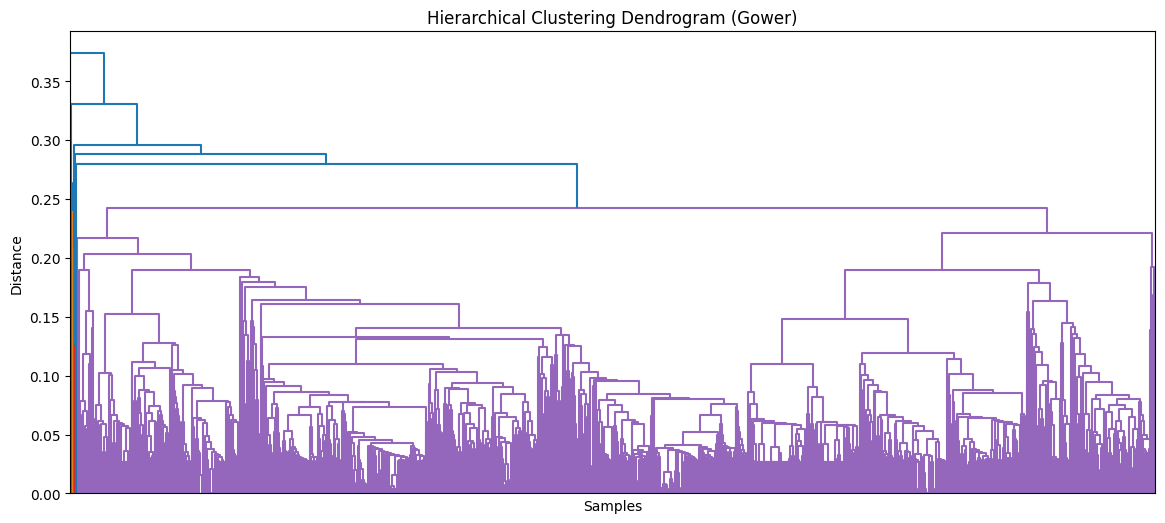

In [ ]:
D_condensed = squareform(D, checks=False)

# Linkage: 'average' is common for distance matrices
Z = linkage(D_condensed, method="average")

plt.figure(figsize=(14, 6))
dendrogram(Z, no_labels=True, color_threshold=None)
plt.title("Hierarchical Clustering Dendrogram (Gower)")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.show()

In [ ]:
k = 5
labels = fcluster(Z, t=k, criterion="maxclust")
X_s = X_s.copy()
X_s["cluster"] = labels
X_s["cluster"].value_counts().sort_index()


,count
cluster,
1,5
2,2
3,2
4,1990
5,1


# 2D Addressing Feature Imbalance

This is highly dependent on the grouping algorithm or model being used. For Kmeans, we can consider scaling (standard scalar), dimenensionality reduction (PCA), log transformation (for highly skewed distributions).

Possibly, need to also identify which patterns are important or significant to business intelligence which can be converted into actions (Demonstrate the commercial value of the dataset by showing how these insights can support decision-making for potential data buyers), find out how?

Possible solution:
In unsupervised learning, Feature Importance is measured by how much a variable contributes to the formation and separation of the groups.


# K-prototypes preparation
1. Remove "Unique Identity" Columns (The High-Cardinality Trap)
K-Prototypes calculates categorical distance based on whether two values are the same or different.

Company Sites, Parent Company, Global Ultimate Company, Domestic Ultimate Company.

Why: These are unique names. Almost every row has a different name. Including them will make every company look "equally far" from everyone else, which prevents the algorithm from finding clusters based on shared traits.

2. Remove "Target/Meta" Columns
Outlier_Count, High outlier flag.

Why: They were used to clean the data. If they are included in the model, the algorithm will likely create one group for "High Scores" and one for "Low Scores." This is circular logic; the model is to find groups based on firmographics, not based on our pre-processing flags.

3. Remove "Calculated Redundancy" (The Double-Counting Problem)
K-Means and K-Prototypes are very sensitive to multicollinearity.

Year Found (Keep Years in operation instead).

Is_Domestic_Ultimate_Flag (Keep Is Domestic Ultimate instead—they are redundant).

Branch, Parent, Subsidiary (These are just "Entity Type" broken out into binary. Keep only the original Entity Type column to let the categorical math handle it).

In [ ]:
# feature_table.info()
# feature_table.head(5)

K_prototype = feature_table.copy()


### Testing
# data_fill_in_missing["Entity Type"].value_counts()
# matches = (feature_table['Subsidiary'] == feature_table['Is subsidiary']).sum()
# print(f"Number of rows where both columns match: {matches}")
# feature_table['Subsidiary'].value_counts()
# feature_table['Is subsidiary'].value_counts()

# Drop columns that are incompatitable with K-prototype
K_prototype = K_prototype.drop(columns=["Company Sites", "Parent Company", "Global Ultimate Company",
                                        "Domestic Ultimate Company", "Outlier_Count", "Year Found",
                                        "Is_Domestic_Ultimate_Flag", "Branch", "Parent", "Subsidiary",
                                        ])

# Adding back "Entity Type", K-prototypes does not require encoding
K_prototype['Entity Type'] = data_fill_in_missing.loc[K_prototype.index, 'Entity Type']

# 2. Ensure it is treated as a 'category' type for K-Prototypes
K_prototype['Entity Type'] = K_prototype['Entity Type'].astype('category')

# Quick transformation to make it a clean flag before the model
K_prototype['Ticker'] = np.where(K_prototype['Ticker'] > 0, 1, 0)
K_prototype['Ticker'] = K_prototype['Ticker'].astype('category')

K_prototype.info()

# 1. Define the Quantitative columns
# These are features where the "distance" between values matters
quantitative_cols = [
    "Employees Total", "Revenue (USD)", "Market Value (USD)",
    "IT Budget", "IT spend", "Corporate Family Members", "Revenue per IT dollar",
    "Years in operation", "Revenue per employee", "Proportion of IT budget spent",
    "IT architecture completeness", "IT spend per employee",
    "IT budget per employee", "Laptop to Desktop ratio", "Servers per 100 employees",
    "IT spend as pct of revenue", "Family members per employee"
]

# 2. Define the Categorical columns (Nominal & Ordinal)
# These will be ignored by the scaler but used by K-Prototypes
categorical_cols = [
    "City", "Entity Type", "Ticker", "Parents City", "Global Ultimate City Name", "Global Ultimate Country Name",
    "Domestic Ultimate City Name", "Legal Status", "Master Industry",  "Is_Headquarters_Flag",
    "Is_Indonesia_Legalization_Registered", "Is_Confirmed_Not_Franchise", "Is_Manufacturing_Firm", "Digital_Presence_Flag",
    "Is subsidiary", "City is parent city", "Is Domestic Ultimate",
    "No. of PC", "No. of Desktops", "No. of Laptops",
    "No. of Routers", "No. of Servers", "No. of Storage Devices",
]

available_quant = [c for c in quantitative_cols if c in K_prototype.columns]

for col in available_quant:
    # Ensure no negative values before log (though firmographic counts should be positive)
    # We use np.maximum to ensure we don't try to log a negative number
    K_prototype[col] = np.log1p(np.maximum(K_prototype[col], 0))

print(f"Log transformation applied to {len(available_quant)} variables.")

# SCALING
scaler = RobustScaler()
K_prototype[available_quant] = scaler.fit_transform(K_prototype[available_quant])

# Apply a "Soft Clip" to prevent any remaining extreme variance from breaking K-Prototypes
K_prototype[available_quant] = K_prototype[available_quant].clip(lower=-15, upper=15)

print(f"Successfully scaled and clipped {len(available_quant)} numeric variables.")

# CATEGORICAL PREPARATION
final_cat_list = [c for c in categorical_cols if c in K_prototype.columns]
cat_indices = [K_prototype.columns.get_loc(col) for col in final_cat_list]

for col in final_cat_list:
    K_prototype[col] = K_prototype[col].astype('category')

print(f"Categorical indices for the model: {cat_indices}")

<class 'pandas.core.frame.DataFrame'>
Index: 8388 entries, 0 to 8557
Data columns (total 41 columns):
 #   Column                                Non-Null Count  Dtype   
---  ------                                --------------  -----   
 0   City                                  8388 non-null   object  
 1   Entity Type                           8388 non-null   category
 2   Employees Total                       8388 non-null   int64   
 3   Revenue (USD)                         8388 non-null   int64   
 4   Ticker                                8388 non-null   category
 5   Parents City                          8388 non-null   object  
 6   Global Ultimate City Name             8388 non-null   object  
 7   Global Ultimate Country Name          8388 non-null   object  
 8   Domestic Ultimate City Name           8388 non-null   object  
 9   Legal Status                          8388 non-null   float64 
 10  Corporate Family Members              8388 non-null   int64   
 11  Is_Headqu

# K-prototype model running and testing

In [ ]:
# 1. Prepare data matrix
# df_matrix = K_prototype.values
# costs = []
# # Expanded range to K=12 to verify the trend beyond the current plateau
# n_clusters_range = range(2, 13)

# print("Starting Automated Elbow Analysis...")

# for k in n_clusters_range:
#     start_time = time.time()
#     # n_init=3 provides better stability for elbow detection than n_init=1
#     kproto = KPrototypes(n_clusters=k, init='Huang', n_init=3, verbose=0, random_state=42)
#     kproto.fit(df_matrix, categorical=cat_indices)

#     costs.append(kproto.cost_)
#     print(f"K={k} completed in {time.time() - start_time:.2f}s. Cost: {kproto.cost_:.2f}")

# # AUTOMATIC K SELECTION
# # S=1.0 is the sensitivity; curve='convex' and direction='decreasing' matches the Elbow plot
# kn = KneeLocator(n_clusters_range, costs, curve='convex', direction='decreasing', S=1.0)
# optimal_k = kn.knee

# print(f"\n>>> Mathematical Optimal K detected: {optimal_k}")

# # 2. Automatically generate the Elbow Plot with the detected Knee
# plt.figure(figsize=(10, 6))
# plt.plot(n_clusters_range, costs, marker='o', linestyle='-', color='b', markersize=8)

# # Vertical line to show where the algorithm "found" the elbow
# if optimal_k:
#     plt.axvline(x=optimal_k, color='r', linestyle='--', label=f'Optimal K={optimal_k}')
#     plt.annotate(f'Automated Elbow (K={optimal_k})',
#                  xy=(optimal_k, costs[optimal_k-2]), # Adjust index for range starting at 2
#                  xytext=(optimal_k+1, costs[optimal_k-2]+5000),
#                  arrowprops=dict(facecolor='black', shrink=0.05),
#                  fontsize=10, fontweight='bold')

# plt.title('Automated Elbow Method for Market Segmentation', fontsize=14)
# plt.xlabel('Number of Clusters (k)', fontsize=12)
# plt.ylabel('Cost (Dissimilarity)', fontsize=12)
# plt.xticks(n_clusters_range)
# plt.legend()
# plt.grid(True, linestyle='--', alpha=0.7)
# plt.show()

optimal_k = 5

kproto_final = KPrototypes(n_clusters=optimal_k, init='Huang', n_init=10, verbose=1, random_state=42)
clusters = kproto_final.fit_predict(K_prototype.values, categorical=cat_indices)

# 3. Add labels back to the dataframe we use for analysis (unscaled data)
feature_table['Cluster_Labels'] = clusters

# 4. Quick check of the cluster sizes
print("Cluster Distribution")
print(feature_table['Cluster_Labels'].value_counts().sort_index())

Init: initializing centroids
Init: initializing clusters
Init: initializing centroids
Init: initializing clusters
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run: 1, iteration: 1/100, moves: 2595, ncost: 3808416.2366241855
Run: 1, iteration: 2/100, moves: 735, ncost: 1123609.7087903765
Run: 1, iteration: 3/100, moves: 425, ncost: 214031.78807080153
Run: 1, iteration: 4/100, moves: 304, ncost: 213131.89816805362
Run: 1, iteration: 5/100, moves: 87, ncost: 212948.7795541565
Run: 1, iteration: 6/100, moves: 144, ncost: 211688.6615447122
Run: 1, iteration: 7/100, moves: 151, ncost: 210789.00741842235
Run: 1, iteration: 8/100, moves: 143, ncost: 209540.37814078561
Run: 1, iteration: 9/100, moves: 109, ncost: 208333.8355304702
Run: 1, iteration: 10/100, moves: 189, ncost: 206635.19194486635
Run: 1, iteration: 11/100, moves: 51, ncost: 206508.2778905009
Run: 1, iteration: 12/100, moves: 94, ncost: 205657.3031219701
Run: 1, iteration: 13/100, moves: 34, ncos

# To save and run the K-prototype model

In [ ]:
# Save the results to a CSV for reporting and visualization (PowerBI/Tableau)
feature_table.to_csv('Firmographic_Clusters_Results.csv', index=False)

print("Results saved to 'Firmographic_Clusters_Results.csv'.")

# Save the trained K-Prototypes model to a file
with open('kproto_model_6_clusters.pkl', 'wb') as f:
    pickle.dump(kproto_final, f)

# Save the Scaler as well
with open('robust_scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print("Model and Scaler saved successfully.")

# To load the results later:
# data_results = pd.read_csv('Firmographic_Clusters_Results.csv')

# To load the model for new data:
# with open('kproto_model_6_clusters.pkl', 'rb') as f:
#    loaded_model = pickle.load(f)

Results saved to 'Firmographic_Clusters_Results.csv'.
Model and Scaler saved successfully.


# K-prototypes results analysis

1. Identify Important Variables (Feature Importance) since K-Prototypes doesn't have a built-in "importance score" like a Random Forest, we use Cluster Centroids and Statistical Differencing to see what makes a cluster stand out.

For Numeric Variables: We look for features where a cluster's mean is significantly higher or lower than the global average (e.g., Cluster 2 has $3\times$ the average IT Spend).

For Categorical Variables: We look at the "Mode" (most frequent value) to see if a cluster is dominated by a specific Industry or City.

2. Analyze Similarities, Differences, and Patterns
Using the tables above, define the "Persona" of each group:

Patterns & Strengths: Look for "High Efficiency" groups (e.g., high revenue with low employee count) or "Tech Leaders" (high IT budget per employee).

Risks: Look for clusters with "Tech Data Incompleteness" or those in industries currently facing economic volatility in Indonesia.

Differences: Contrast the "Mega-Corps" against "Agile Mid-Market".

3. Cross-Reference with anomalies_df, we merge our cluster labels with our original anomaly data, so that we can see if specific clusters are "Anomaly Magnets."

# Results
1. Distinguishing Important Variables for Executives
The Cluster Numeric Profiles table allows identifying which variables act as "differentiators" for each group. By comparing the averages across clusters, one can determine what defines a segment's behavior.

Key Actionable Insights:

Revenue vs. IT Spend Efficiency: Segments like cluster 4 can be examined, which shows the highest average Revenue and Market Value, alongside high IT Spend. This highlights them as the "Enterprise Leaders" where high IT investment correlates with high output.

Infrastructure Completeness: Cluster 0 has the highest "IT architecture completeness" score (5.53), suggesting these firms are technically mature and potentially better targets for advanced software solutions rather than basic hardware.

Longevity: Cluster 3 has significantly fewer "Years in operation" (7.78) compared to others like Cluster 1 (22.9), allowing executives to distinguish between established legacy firms and younger, emerging companies.

2. Analysis of Similarities, Differences, Patterns, and Risk
The combination of numeric and categorical profiles reveals the structural patterns of your data.

Similarities and Patterns:

Geography and Industry: Clusters 1, 3, and 4 are dominated by firms in Kunming, primarily in the Services or Retail Trade sectors. This indicates a geographic concentration that could simplify localized marketing strategies.

Legal Structure: Most clusters (0, 1, 2, 3) are composed of Subsidiaries or Branches, while Cluster 4 uniquely contains Parent companies. This is a major differentiator for decision-making authority.

Strengths and Risks:

Cluster 2 (The Risk Segment): This cluster is marked by "Unknown" city data and low digital presence flags. Combined with lower infrastructure scores, this group represents a high-risk or data-incomplete segment that may require manual verification.

Cross-Referencing Anomalies: Filter anomalies_df by these Cluster_Labels. If a cluster has a high average "Revenue per employee" but very low "IT Spend," and these firms also appear in your anomalies_df, they are mathematically flagged as highly unusual and should be prioritized for audit.

3. The "Safe Zones" vs. "Wildcards"
The Anomaly Lift is the most important metric to analyze.

Low Risk (Clusters 2 & 3): These segments have a lift score significantly below 1.0 (0.11 and 0.13). This means they are highly stable. Business processes for these groups (like automated credit approvals or marketing) can be scaled with high confidence.

High Risk (Cluster 0): This is your primary Anomaly Magnet. With a lift of 2.36, companies in this cluster are 2.36 times more likely than the average firm to have "weird" or non-standard firmographics. Decisions regarding this group should require manual audit or additional verification.

4. Identifying "Market Noise" (Cluster 1)
While Cluster 0 has the highest relative risk, Cluster 1 contains the highest volume of anomalies (107 out of 170).

]Takeaway: Cluster 1 is a "noisy" segment. It may represent a broad industry where data is naturally inconsistent. When reviewing Cluster 1, executives should expect "non-standard" entities and should not rely solely on automated summary statistics.

In [ ]:
# 1. Filter lists to only include columns that actually exist in feature_table
available_quant = [c for c in quantitative_cols if c in feature_table.columns]
available_cat = [c for c in categorical_cols if c in feature_table.columns]

print(f"Analyzing {len(available_quant)} numeric and {len(available_cat)} categorical variables.")

# 2. Group by labels and calculate means for numeric data
cluster_profiles_num = feature_table.groupby('Cluster_Labels')[available_quant].mean()

# 3. Add the count of firms in each cluster
cluster_profiles_num['Firm_Count'] = feature_table['Cluster_Labels'].value_counts()

# 4. Identify the most common Category (Mode) for each cluster
# We use .apply(lambda x: x.mode().iloc[0]) to ensure we get a single value if there's a tie
cluster_profiles_cat = feature_table.groupby('Cluster_Labels')[available_cat].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)

# Display the summary
print("\nCluster Numeric Profiles (Averages)")
display(cluster_profiles_num.style.background_gradient(cmap='Blues'))

print("\nCluster Categorical Profiles (Dominant Traits)")
display(cluster_profiles_cat)

# Check Quantitative Columns
missing_quant = [c for c in quantitative_cols if c not in feature_table.columns]

# Check Categorical Columns
missing_cat = [c for c in categorical_cols if c not in feature_table.columns]

print("Missing Quantitative Columns")
print(missing_quant if missing_quant else "None")

print("\nMissing Categorical Columns")
print(missing_cat if missing_cat else "None")

# 1. Feature Engineer the anomalies
anomalies_engineered = feature_engineering(anomalies_df)

# 2. Match the columns to K_prototype (Modeling Dataframe)
# Drop the same columns we dropped for the main model
anomalies_modeling = anomalies_engineered.drop(columns=[
    "Company Sites", "Parent Company", "Global Ultimate Company",
    "Domestic Ultimate Company", "Outlier_Count", "Year Found",
    "Is_Domestic_Ultimate_Flag", "Branch", "Parent", "Subsidiary"
], errors='ignore')

# 3. Apply Log-Transform and Scaling using the ALREADY TRAINED scaler
# We use .transform() NOT .fit_transform() to keep the scaling identical
for col in available_quant:
    anomalies_modeling[col] = np.log1p(np.maximum(anomalies_modeling[col], 0))

anomalies_modeling[available_quant] = scaler.transform(anomalies_modeling[available_quant])
anomalies_modeling[available_quant] = anomalies_modeling[available_quant].clip(lower=-15, upper=15)

# 4. Set Category types for anomalies
for col in final_cat_list:
    anomalies_modeling[col] = anomalies_modeling[col].astype('category')

# Predict which cluster these outliers belong to
anomaly_clusters = kproto_final.predict(anomalies_modeling.values, categorical=cat_indices)
anomalies_df['Assigned_Cluster'] = anomaly_clusters

# THE ANOMALY MAGNET REPORT
print("Anomaly Magnet Distribution")
magnet_distribution = anomalies_df['Assigned_Cluster'].value_counts().sort_index()
print(magnet_distribution)

# Calculate "Anomaly Pressure" per cluster
# (How many anomalies were attracted to this cluster relative to the cluster's size)
cluster_sizes = feature_table['Cluster_Labels'].value_counts()
anomaly_pressure = (magnet_distribution / cluster_sizes).fillna(0)

print("\nAnomaly Pressure (Relative Risk)")
print(anomaly_pressure.sort_values(ascending=False))

# 1. Calculate the Global Baseline
total_anomalies = len(anomalies_df)
total_majority = len(feature_table)
global_rate = total_anomalies / (total_anomalies + total_majority)

# 2. Calculate Lift (How much more likely is an anomaly here?)
# anomaly_pressure is your (magnet_distribution / cluster_sizes)
anomaly_lift = anomaly_pressure / global_rate

print(f"Global Anomaly Rate: {global_rate:.2%}")
print("\nAnomaly Lift (Weighted Risk Score)")
# A score of 2.0 means 2x the average risk
print(anomaly_lift.sort_values(ascending=False))

Analyzing 17 numeric and 22 categorical variables.

Cluster Numeric Profiles (Averages)


,Employees Total,Revenue (USD),Market Value (USD),IT Budget,IT spend,Corporate Family Members,Revenue per IT dollar,Years in operation,Revenue per employee,Proportion of IT budget spent,IT architecture completeness,IT spend per employee,IT budget per employee,Laptop to Desktop ratio,Servers per 100 employees,IT spend as pct of revenue,Family members per employee,Firm_Count
Cluster_Labels,,,,,,,,,,,,,,,,,,
0,12.394764,1841068.634516,5876650.594902,81507.737513,50534.579401,873.120565,26.664698,9.263865,550164.606364,0.318137,4.600758,15789.367182,25466.840199,0.500214,0.455706,0.017684,422.914324,2903
1,28.098361,7913976.009563,14946164.217213,247545.635929,153477.856557,333.795765,2023059.872359,22.178279,4630438.223479,0.551237,5.252049,60176.274384,97058.697066,0.500223,0.626023,0.028747,90.200323,1464
2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2026.000000,0.000000,0.000000,5.000000,0.000000,0.000000,0.500000,1.000000,0.000000,0.000000,1
3,32.642633,18077394.846395,23104761.153605,336636.492163,208714.175549,963.752351,6938337.843365,39.664577,12512646.010423,0.569186,4.993730,97884.655268,157878.734305,0.500075,0.533345,0.026476,277.401361,319
4,13.221292,1542961.679816,5069308.286949,75787.720346,46957.747366,434.651986,11.612503,3.292083,243704.280185,0.333439,4.805728,7736.895407,12527.969095,0.500000,0.523875,0.019859,345.149276,3701



Cluster Categorical Profiles (Dominant Traits)


,City,Entity Type,Ticker,Parents City,Global Ultimate City Name,Global Ultimate Country Name,Domestic Ultimate City Name,Legal Status,Master Industry,Is_Headquarters_Flag,Is_Indonesia_Legalization_Registered,Is_Confirmed_Not_Franchise,Is_Manufacturing_Firm,Digital_Presence_Flag,City is parent city,Is Domestic Ultimate,No. of PC,No. of Desktops,No. of Laptops,No. of Routers,No. of Servers,No. of Storage Devices
Cluster_Labels,,,,,,,,,,,,,,,,,,,,,,
0,Kunming,Branch,0.0,Kunming,Kunming,CHINA,Kunming,3.0,Services,0,0,0,0,0,1,0,1.0,1.0,1.0,1,1.0,1.0
1,Zhengzhou,Parent,0.0,Zhengzhou,Zhengzhou,CHINA,Zhengzhou,3.0,Manufacturing,0,0,0,0,0,1,0,1.0,1.0,1.0,1,1.0,1.0
2,Unknown,Branch,0.0,Standalone,Standalone,CHINA,Standalone,-1.0,Nonclassifiable,0,0,0,0,0,0,0,1.0,1.0,1.0,0,1.0,1.0
3,Zhongshan,Parent,0.0,Zhongshan,Standalone,CHINA,Standalone,3.0,Services,0,0,0,0,0,1,1,1.0,1.0,1.0,1,1.0,1.0
4,Unknown,Subsidiary,0.0,Kunming,Kunming,CHINA,Kunming,3.0,Services,0,0,0,0,0,1,0,1.0,1.0,1.0,1,1.0,1.0


Missing Quantitative Columns
None

Missing Categorical Columns
['Is subsidiary']


ValueError: operands could not be broadcast together with shapes (5,19) (18,) 

# KNN clustering algorithm

In [ ]:
#Cluster by scale, financial capacity and digital infrastructure
cluster_features = [
    "Employees Total",
    "Revenue (USD)",
    "Corporate Family Members",
    "Market Value (USD)",
    "IT spend",
    "IT Budget",
    #'Total Devices',
    #"Years in operation",
    #"Devices per employee",
    #'Proportion of Budget spent',
    #"Market cap to revenue ratio"
]
X = feature_table[cluster_features].copy()

print(X.isna().sum().sum())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled

0


array([[-0.37740464, 65.9083062 , -0.13478193, -0.16571126, -0.14264857,
        -0.14267545],
       [-0.37740464, 49.23472001, -0.12738228, -0.16571126, -0.14264857,
        -0.14267545],
       [11.22160076, 21.86664497, -0.12900095, -0.16571126, 33.2982409 ,
        33.2982422 ],
       ...,
       [-0.37740464, -0.07545227, -0.13362573, -0.16571126, -0.14264857,
        -0.14267545],
       [-0.37740464, -0.07545227, -0.13431945, -0.16571126, -0.14264857,
        -0.14267545],
       [-0.37740464, -0.07545227, -0.12622609, -0.16571126, -0.14264857,
        -0.14267545]])

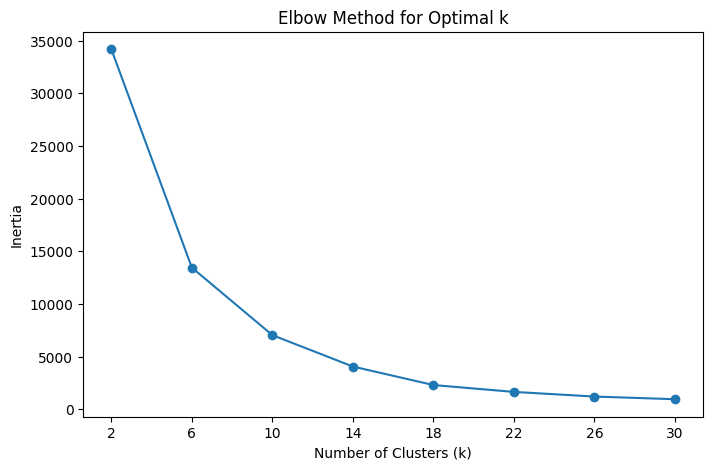

In [ ]:
inertia = []
K_range = range(2, 32, 4)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.xticks(range(2, 32, 4))
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.show()


In [ ]:
kmeans = KMeans(n_clusters = 14,random_state = 42, n_init=10)
feature_table["Cluster"] = kmeans.fit_predict(X_scaled)
cluster_profile = (
    feature_table
    .groupby("Cluster")[cluster_features]
    .mean()
    .round(2)
)

print(np.unique(kmeans.labels_, return_counts=True))
print(kmeans.cluster_centers_)

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13],
      dtype=int32), array([5483,    4,   21,    4,    2,   51,    1,   64,    6,    1, 2268,
        310,  168,    5]))
[[-2.98934188e-01 -6.27674648e-02 -9.92313534e-02 -1.32163843e-01
  -1.08637451e-01 -1.08623742e-01]
 [-8.74295083e-02  6.36804004e+00  8.05338924e+00  1.77024185e+01
   2.09204040e+01  2.09203946e+01]
 [ 3.63827035e-01  1.24482582e-01  1.65401119e+01  3.38002028e-02
   4.11697554e-01  4.11671723e-01]
 [-3.77404644e-01  9.76659781e+00 -1.29752480e-01  3.39211186e+01
   1.21205738e+01  1.21205577e+01]
 [-3.77404644e-01  5.75715131e+01 -1.31082104e-01 -1.65711263e-01
  -1.42648567e-01 -1.42675452e-01]
 [ 6.17989975e+00  8.07016255e-02 -1.18128189e-01  2.90302750e-01
   1.04914745e-01  1.04888808e-01]
 [ 2.02545627e-01  1.43178380e+01  9.16010034e-02 -1.65711263e-01
   6.17485428e+01  6.17485664e+01]
 [ 1.24252340e-01  1.12304708e+00 -7.45983778e-02  2.81732065e+00
   2.47677396e+00  2.47675017e+00]
 [ 2.35

Cluster 0, 1, 8, 10, 13 are important. Here are their centroids.

In [ ]:
df1 = cluster_profile.loc[0:1]
df2 = cluster_profile.loc[8:10]
df3 = cluster_profile.loc[13]
df3 = df3.to_frame().T
df = pd.concat([df1, df2, df3])
df

,Employees Total,Revenue (USD),Corporate Family Members,Market Value (USD),IT spend,IT Budget
0,3.38,5.693662e+05,159.74,1.570543e+06,17389.17,28080.51
1,12.50,2.892207e+08,35416.00,8.365072e+08,10769098.00,17369513.50
8,1029.83,1.416228e+06,32.83,4.332946e+06,22697.83,36609.83
9,500.00,9.848864e+08,31.00,0.000000e+00,17097627.00,27576819.00
10,26.84,3.903779e+06,87.62,1.242040e+07,113222.07,182616.87
13,22.00,2.146456e+08,39.80,7.084251e+08,2650896.40,4275640.40


Cluster 0: Micro Ventures : 4 employees, $197K revenue
Mainly Solo founders with small networks, Minimal tech spend, highest risk

Cluster 1: Stable SMBs: 22 employees, $1.9M revenue
Classic small businesses, balanced operations, perfect for mid-market solutions

Cluster 2: High-Performance SMEs: 22 employees but $3.8M revenue (twice Cluster 1)
Tech-driven, most efficient, highest IT investment, Premium customers for enterprise solutions

Cluster 3: Holding Companies: 6 employees, $333K revenue, 63 corporate family members (extreme complexity)
Corporate shells, need compliance/governance tools

Key Insight: Cluster 2 proves efficiency matters more than size.

Commercial Strategy: Target Cluster 2 for highest ROI, upsell Cluster 1, specialized solutions for Cluster 3.

# HDBSCAN from scikit-learn

In [ ]:
feature_table.head()

,Company Sites,City,Entity Type,Employees Total,Revenue (USD),Ticker,Year Found,Parent Company,Parents City,Global Ultimate Company,Global Ultimate City Name,Global Ultimate Country Name,Domestic Ultimate Company,Domestic Ultimate City Name,Legal Status,Corporate Family Members,Is_Headquarters_Flag,Is_Domestic_Ultimate_Flag,Market Value (USD),IT Budget,IT spend,No. of PC,No. of Desktops,No. of Laptops,No. of Routers,No. of Servers,No. of Storage Devices,Master Industry,Is_Indonesia_Legalization_Registered,Is_Confirmed_Not_Franchise,Is_Manufacturing_Firm,Digital_Presence_Flag,Outlier_Count,Company_Age,Branch,Parent,Subsidiary,Is Domestic Ultimate,Years in operation,Proportion of IT budget spent,IT budget per employee,City is parent city,City is domestic ultimate,IT architecture completeness,Revenue per IT dollar,Revenue per employee,Family members per employee,IT spend per employee,Laptop to Desktop ratio,Servers per 100 employees,IT spend as pct of revenue,Cluster_Labels,Cluster
0,"Zhejiang Mingye Construction Co., Ltd. ...",Hangzhou,Parent,0,2961727200,0.0,2007.0,"Zhejiang Mingye Construction Co., Ltd. ...",Hangzhou,"Zhejiang Mingye Construction Co., Ltd. ...",Hangzhou,CHINA,"Zhejiang Mingye Construction Co., Ltd. ...",Hangzhou,3.0,6,1,1,0,0,0,1.0,1.0,1.0,0,0.0,0.0,Construction,0,0,0,0,1,19.0,0,1,0,1,19.0,0.00,0.000000e+00,1,1,3,2.961727e+09,2.961727e+09,6.000000,0.000000e+00,0.5,0.0,0.00000,1,4
1,"Yonfer Agricultural Technology Co., Ltd. ...",Jingmen,Parent,0,2213321609,902.0,1986.0,"Yonfer Agricultural Technology Co., Ltd. ...",Jingmen,"Yonfer Agricultural Technology Co., Ltd. ...",Jingmen,CHINA,"Yonfer Agricultural Technology Co., Ltd. ...",Jingmen,8.0,38,0,0,0,0,0,1.0,1.0,1.0,0,0.0,0.0,Manufacturing,0,0,1,1,5,40.0,0,1,0,1,40.0,0.00,0.000000e+00,1,1,3,2.213322e+09,2.213322e+09,38.000000,0.000000e+00,0.5,0.0,0.00000,3,4
2,"Yimen Copper Industry Co., Ltd. ...",Yuxi,Subsidiary,500,984886398,0.0,1995.0,"Yunnan Copper Co., Ltd. ...",Kunming,"Yunnan Copper Co., Ltd. ...",Kunming,CHINA,"Yunnan Copper Co., Ltd. ...",Kunming,3.0,31,0,0,0,27576819,17097627,4.0,1.0,1.0,2,0.0,3.5,Manufacturing,0,0,1,0,7,31.0,0,0,1,0,31.0,0.62,5.504355e+04,0,0,5,3.571428e+01,1.965841e+06,0.061876,3.412700e+04,0.5,0.0,0.01736,3,9
3,"Hangzhou Yage'er Property Co., Ltd. ...",Hangzhou,Subsidiary,25,646052913,0.0,2007.0,"Youngor Real Estate Holding Co., Ltd. ...",Ningbo,"Youngor Group Co., Ltd. ...",Ningbo,CHINA,"Youngor Group Co., Ltd. ...",Ningbo,3.0,985,0,0,0,51038180,31643671,2.0,1.0,1.0,1,1.0,1.0,Construction,0,0,0,0,4,19.0,0,0,1,0,19.0,0.62,1.963007e+06,0,0,6,1.265823e+01,2.484819e+07,37.884615,1.217064e+06,0.5,0.8,0.04898,1,6
4,"Sinosteel Shipping& Forwarding Co., Ltd. ...",Beijing,Subsidiary,0,518268069,0.0,1994.0,"Zhonggang International Trade Co., Ltd. ...",Beijing,Restricted Data - Order Investigation 54495771...,Standalone,CHINA,Restricted Data - Order Investigation 54495771...,Standalone,3.0,70723,1,1,1300852853,15548042,9639786,1.0,1.0,1.0,0,0.0,0.0,Transportation and storage,0,0,0,1,6,32.0,0,0,1,0,32.0,0.62,1.554804e+07,1,0,3,3.333333e+01,5.182681e+08,70723.000000,9.639786e+06,0.5,0.0,0.01860,3,1


In [ ]:
# Binary/integer flags (can treat as continuous or categorical)
feature2 = feature_table.drop(columns=['Company Sites', 'City', 'Cluster_Labels', 'Cluster', 'Parent Company', 'Parents City', 'Global Ultimate Company', 'Global Ultimate City Name', 'Global Ultimate Country Name', 'Domestic Ultimate Company', 'Domestic Ultimate City Name', 'Master Industry','Legal Status', 'Entity Type', 'Ticker'],
                   errors='ignore')

feature2

,Employees Total,Revenue (USD),Year Found,Corporate Family Members,Is_Headquarters_Flag,Is_Domestic_Ultimate_Flag,Market Value (USD),IT Budget,IT spend,No. of PC,No. of Desktops,No. of Laptops,No. of Routers,No. of Servers,No. of Storage Devices,Is_Indonesia_Legalization_Registered,Is_Confirmed_Not_Franchise,Is_Manufacturing_Firm,Digital_Presence_Flag,Outlier_Count,Company_Age,Branch,Parent,Subsidiary,Is Domestic Ultimate,Years in operation,Proportion of IT budget spent,IT budget per employee,City is parent city,City is domestic ultimate,IT architecture completeness,Revenue per IT dollar,Revenue per employee,Family members per employee,IT spend per employee,Laptop to Desktop ratio,Servers per 100 employees,IT spend as pct of revenue
0,0,2961727200,2007.0,6,1,1,0,0,0,1.0,1.0,1.0,0,0.0,0.0,0,0,0,0,1,19.0,0,1,0,1,19.0,0.00,0.000000e+00,1,1,3,2.961727e+09,2.961727e+09,6.000000,0.000000e+00,0.5,0.0,0.00000
1,0,2213321609,1986.0,38,0,0,0,0,0,1.0,1.0,1.0,0,0.0,0.0,0,0,1,1,5,40.0,0,1,0,1,40.0,0.00,0.000000e+00,1,1,3,2.213322e+09,2.213322e+09,38.000000,0.000000e+00,0.5,0.0,0.00000
2,500,984886398,1995.0,31,0,0,0,27576819,17097627,4.0,1.0,1.0,2,0.0,3.5,0,0,1,0,7,31.0,0,0,1,0,31.0,0.62,5.504355e+04,0,0,5,3.571428e+01,1.965841e+06,0.061876,3.412700e+04,0.5,0.0,0.01736
3,25,646052913,2007.0,985,0,0,0,51038180,31643671,2.0,1.0,1.0,1,1.0,1.0,0,0,0,0,4,19.0,0,0,1,0,19.0,0.62,1.963007e+06,0,0,6,1.265823e+01,2.484819e+07,37.884615,1.217064e+06,0.5,0.8,0.04898
4,0,518268069,1994.0,70723,1,1,1300852853,15548042,9639786,1.0,1.0,1.0,0,0.0,0.0,0,0,0,1,6,32.0,0,0,1,0,32.0,0.62,1.554804e+07,1,0,3,3.333333e+01,5.182681e+08,70723.000000,9.639786e+06,0.5,0.0,0.01860
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8553,0,0,2015.0,13,0,0,0,0,0,1.0,1.0,1.0,0,0.0,0.0,0,0,0,0,4,11.0,1,0,0,0,11.0,0.00,0.000000e+00,1,1,3,0.000000e+00,0.000000e+00,13.000000,0.000000e+00,0.5,0.0,0.00000
8554,0,0,2018.0,2,0,0,0,0,0,1.0,1.0,1.0,0,0.0,0.0,0,0,0,0,4,8.0,1,0,0,0,8.0,0.00,0.000000e+00,1,1,3,0.000000e+00,0.000000e+00,2.000000,0.000000e+00,0.5,0.0,0.00000
8555,0,0,2019.0,11,0,0,0,0,0,1.0,1.0,1.0,0,1.0,1.0,0,0,0,1,0,7.0,1,0,0,0,7.0,0.00,0.000000e+00,0,0,5,0.000000e+00,0.000000e+00,11.000000,0.000000e+00,0.5,1.0,0.00000
8556,0,0,2018.0,8,0,0,0,0,0,1.0,1.0,1.0,0,0.0,0.0,0,0,0,0,0,8.0,1,0,0,0,8.0,0.00,0.000000e+00,0,0,3,0.000000e+00,0.000000e+00,8.000000,0.000000e+00,0.5,0.0,0.00000


In [ ]:
binary_cols = [
    'Is_Indonesia_Legalization_Registered', 'Is_Confirmed_Not_Franchise',
    'Is_Manufacturing_Firm', 'Digital_Presence_Flag',
    'Branch', 'Parent', 'Subsidiary', 'Is Domestic Ultimate',
    'City is parent city', 'City is domestic ultimate'
]

continuous_cols = [
    'Employees Total', 'Revenue (USD)', 'Market Value (USD)',
    'IT Budget', 'IT spend', 'No. of Routers', 'Corporate Family Members',
    'Years in operation', 'Proportion of IT budget spent',
    'IT architecture completeness', 'Revenue per IT dollar',
    'Revenue per employee', 'Family members per employee',
    'IT spend per employee', 'Laptop to Desktop ratio',
    'Servers per 100 employees', 'IT spend as pct of revenue'
]

# Handle missing values and prepare features
# Drop rows with too many missing values or fill strategically
df_clean = feature2[binary_cols + continuous_cols].copy()
df_clean = df_clean.dropna(thresh=len(df_clean.columns) * 0.7)  # Keep rows with at least 70% non-null

# Fill remaining missing values
for col in binary_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna(0)

for col in continuous_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Verify which columns actually exist
existing_binary = [col for col in binary_cols if col in df_clean.columns]
existing_continuous = [col for col in continuous_cols if col in df_clean.columns]

# Option 1: Scale continuous, keep binary as-is (concatenate)
scaler = StandardScaler()
X_continuous = scaler.fit_transform(df_clean[existing_continuous])
X_binary = df_clean[existing_binary].values

X_transformed = np.hstack([X_continuous, X_binary])

print(f"Data shape: {X_transformed.shape}")
print(f"Continuous features: {len(existing_continuous)}")
print(f"Binary features: {len(existing_binary)}")

Data shape: (8388, 27)
Continuous features: 17
Binary features: 10


In [ ]:
df_clean

,Is_Indonesia_Legalization_Registered,Is_Confirmed_Not_Franchise,Is_Manufacturing_Firm,Digital_Presence_Flag,Branch,Parent,Subsidiary,Is Domestic Ultimate,City is parent city,City is domestic ultimate,Employees Total,Revenue (USD),Market Value (USD),IT Budget,IT spend,No. of Routers,Corporate Family Members,Years in operation,Proportion of IT budget spent,IT architecture completeness,Revenue per IT dollar,Revenue per employee,Family members per employee,IT spend per employee,Laptop to Desktop ratio,Servers per 100 employees,IT spend as pct of revenue
0,0,0,0,0,0,1,0,1,1,1,0,2961727200,0,0,0,0,6,19.0,0.00,3,2.961727e+09,2.961727e+09,6.000000,0.000000e+00,0.5,0.0,0.00000
1,0,0,1,1,0,1,0,1,1,1,0,2213321609,0,0,0,0,38,40.0,0.00,3,2.213322e+09,2.213322e+09,38.000000,0.000000e+00,0.5,0.0,0.00000
2,0,0,1,0,0,0,1,0,0,0,500,984886398,0,27576819,17097627,2,31,31.0,0.62,5,3.571428e+01,1.965841e+06,0.061876,3.412700e+04,0.5,0.0,0.01736
3,0,0,0,0,0,0,1,0,0,0,25,646052913,0,51038180,31643671,1,985,19.0,0.62,6,1.265823e+01,2.484819e+07,37.884615,1.217064e+06,0.5,0.8,0.04898
4,0,0,0,1,0,0,1,0,1,0,0,518268069,1300852853,15548042,9639786,0,70723,32.0,0.62,3,3.333333e+01,5.182681e+08,70723.000000,9.639786e+06,0.5,0.0,0.01860
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8553,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,13,11.0,0.00,3,0.000000e+00,0.000000e+00,13.000000,0.000000e+00,0.5,0.0,0.00000
8554,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,2,8.0,0.00,3,0.000000e+00,0.000000e+00,2.000000,0.000000e+00,0.5,0.0,0.00000
8555,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,11,7.0,0.00,5,0.000000e+00,0.000000e+00,11.000000,0.000000e+00,0.5,1.0,0.00000
8556,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,8,8.0,0.00,3,0.000000e+00,0.000000e+00,8.000000,0.000000e+00,0.5,0.0,0.00000


In [ ]:
np.random.seed(42)
# Define parameter grid
param_grid = {
    'min_cluster_size': [200, 300, 500, 700, 1000],
    'min_samples': [10, 20, 30, 50, 100],
    'cluster_selection_epsilon': [0.0, 0.1, 0.2, 0.5],
    'metric': ['euclidean', 'manhattan', 'chebyshev', 'hamming'],
    'cluster_selection_method': ['eom', 'leaf']
}

# Generate all combinations
param_combinations = list(product(*param_grid.values()))
param_keys = list(param_grid.keys())

print(f"Total combinations to test: {len(param_combinations)}")

# Grid search with validation
best_score = -np.inf
best_params = None
results = []

for params in tqdm(param_combinations, desc="Grid Search"):
    param_dict = dict(zip(param_keys, params))

    # Skip invalid combinations
    if param_dict['min_samples'] > param_dict['min_cluster_size']:
        continue

    try:
        # Fit HDBSCAN
        clusterer = HDBSCAN(
            **param_dict,
            core_dist_n_jobs=-1,  # Use all cores
            gen_min_span_tree = True
        )
        labels = clusterer.fit_predict(X_transformed)

        # Calculate metrics
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = np.sum(labels == -1)
        noise_ratio = n_noise / len(labels)

        # Skip if only noise or only one cluster
        if n_clusters < 2:
            continue

        # Use DBCV score (relative_validity_)
        score = clusterer.relative_validity_

        # Additional constraint: don't accept too much noise
        if noise_ratio > 0.5:  # Skip if more than 50% noise
            continue

        results.append({
            'min_cluster_size': param_dict['min_cluster_size'],
            'min_samples': param_dict['min_samples'],
            'cluster_selection_epsilon': param_dict['cluster_selection_epsilon'],
            'metric': param_dict['metric'],
            'cluster_selection_method': param_dict['cluster_selection_method'],
            'dbcv_score': score,
            'n_clusters': n_clusters,
            'n_noise': n_noise,
            'noise_ratio': noise_ratio,
            'largest_cluster_size': np.max(np.bincount(labels[labels >= 0])) if n_clusters > 0 else 0
        })

        if score > best_score:
            best_score = score
            best_params = param_dict
            best_labels = labels

    except Exception as e:
        print(e)

# Convert to DataFrame and analyze
results_df = pd.DataFrame(results).sort_values('dbcv_score', ascending=False)
print("\n" + "="*80)
print("BEST PARAMETERS:")
print("="*80)
print(best_params)
print(f"\nBest DBCV Score: {best_score:.4f}")
print(f"Number of clusters: {len(set(best_labels)) - (1 if -1 in best_labels else 0)}")
print(f"Noise points: {np.sum(best_labels == -1)} ({np.sum(best_labels == -1)/len(best_labels)*100:.1f}%)")

print("\n" + "="*80)
print("TOP 10 CONFIGURATIONS:")
print("="*80)
print(results_df.head(10).to_string())

Total combinations to test: 800


Grid Search: 100%|██████████| 800/800 [1:10:29<00:00,  5.29s/it]


BEST PARAMETERS:
{'min_cluster_size': 1000, 'min_samples': 30, 'cluster_selection_epsilon': 0.0, 'metric': 'euclidean', 'cluster_selection_method': 'eom'}

Best DBCV Score: 0.3883
Number of clusters: 4
Noise points: 2611 (31.1%)

TOP 10 CONFIGURATIONS:
     min_cluster_size  min_samples  cluster_selection_epsilon     metric cluster_selection_method  dbcv_score  n_clusters  n_noise  noise_ratio  largest_cluster_size
642              1000           30                        0.5  euclidean                     leaf    0.388293           4     2611     0.311278                  2229
641              1000           30                        0.5  euclidean                      eom    0.388293           4     2611     0.311278                  2229
636              1000           30                        0.2  euclidean                     leaf    0.388293           4     2611     0.311278                  2229
629              1000           30                        0.1  euclidean          

Using the top configuration of eps = 0.3, min_samples = 50, metric = 'manhattan', n_clusters = 14, we train another similar model to find its DBCV score

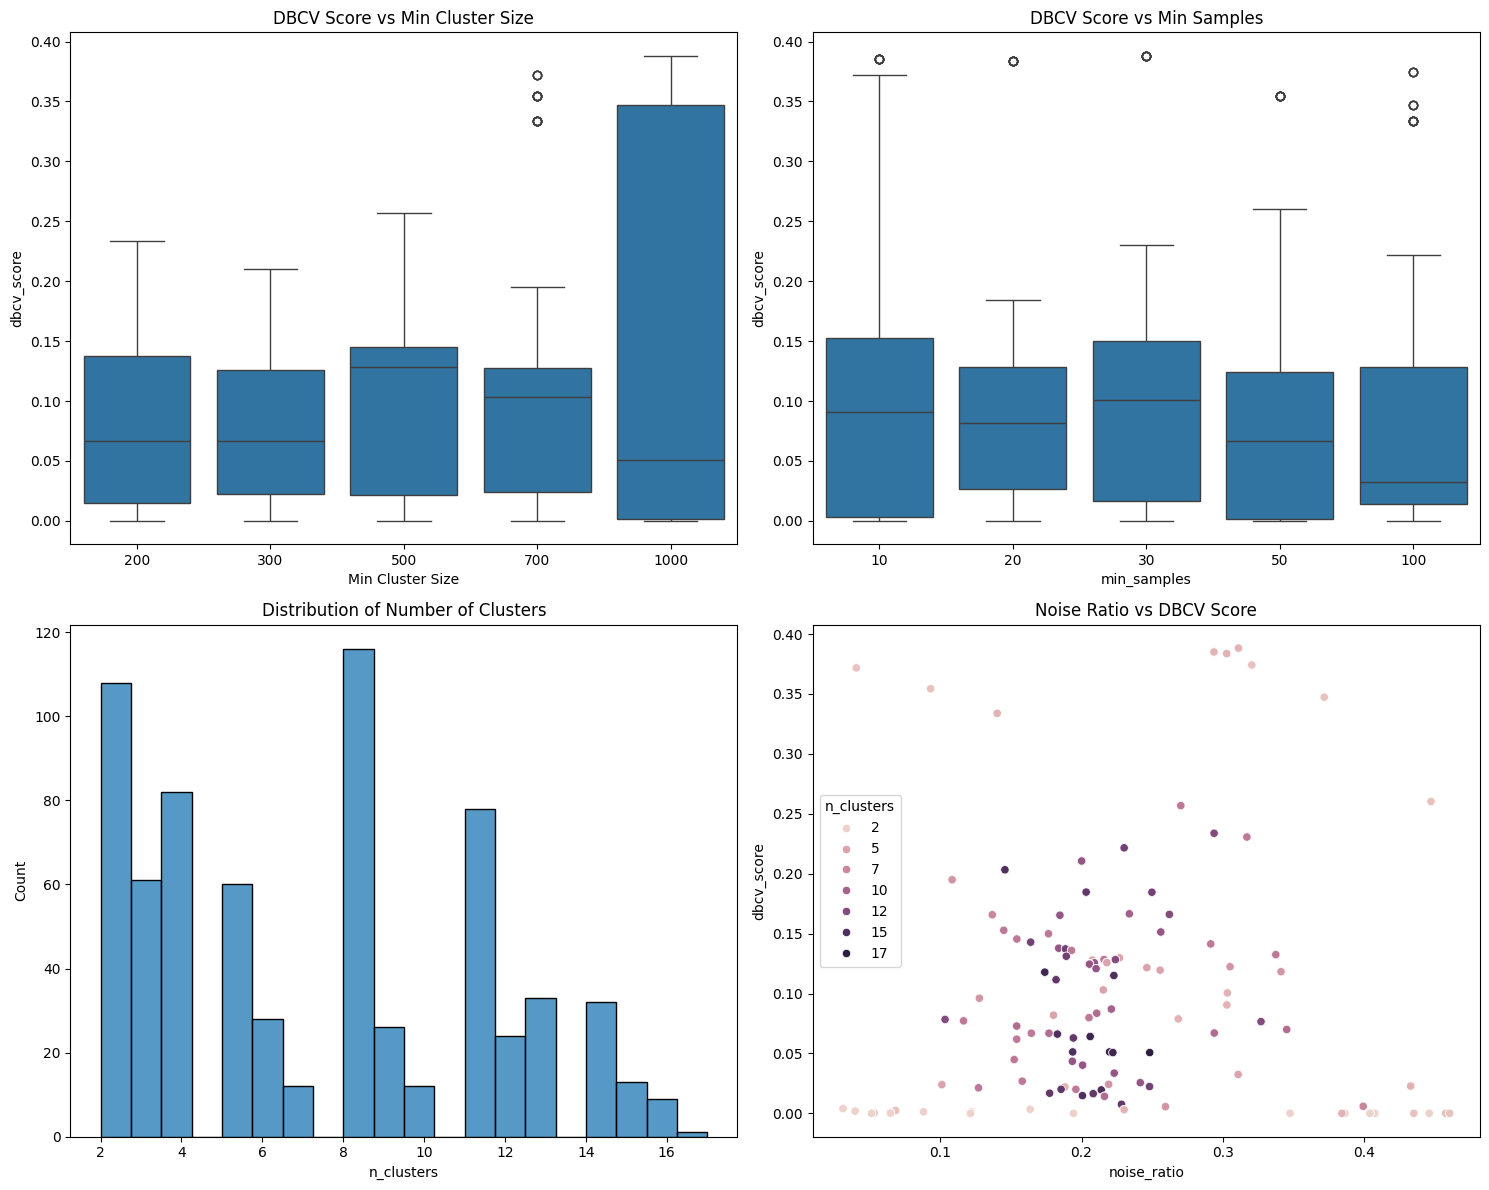

CLUSTER SUMMARY STATISTICS:


,Employees Total,Revenue (USD),Market Value (USD),IT Budget,IT spend,Corporate Family Members,Revenue per IT dollar,Years in operation,Revenue per employee,Proportion of IT budget spent,IT architecture completeness,IT spend per employee,Laptop to Desktop ratio,Servers per 100 employees,IT spend as pct of revenue,Family members per employee,Firm_Count
Cluster,,,,,,,,,,,,,,,,,
-1,27.687859,8535081.630793,17126833.750287,257189.816928,159457.231329,966.675220,1982043.074021,17.320184,4964184.605717,0.604058,4.760628,70195.677095,0.500372,0.493219,0.030455,491.921370,2611
0,4.999017,40.914454,0.000000,0.000000,0.000000,418.841691,40.914454,7.228122,40.914454,0.000000,5.420846,0.000000,0.500000,0.963978,0.000000,115.222825,1017
1,0.384477,0.000000,0.000000,81.430238,0.000000,811.537461,0.000000,6.709287,0.000000,0.000000,3.276357,0.000000,0.500000,0.000000,0.000000,589.355993,2229
2,24.157811,2737895.851705,9295574.975416,134567.042030,83431.143537,122.441713,21.346942,6.106265,132151.049504,0.619953,5.997621,4355.568005,0.500000,0.816082,0.037730,6.920372,1261
3,21.862992,2102556.566929,6797753.466929,114573.233858,71034.966929,20.600787,21.114878,8.658268,111340.898256,0.619867,6.000000,3953.361740,0.500000,0.828480,0.038009,1.317049,1270


,Is_Indonesia_Legalization_Registered,Is_Confirmed_Not_Franchise,Is_Manufacturing_Firm,Digital_Presence_Flag,City is parent city,Is Domestic Ultimate,No. of Routers
Cluster,,,,,,,
-1,0,0,0,0,1,1,1
0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0
2,0,0,0,0,0,0,1
3,0,0,0,0,1,0,1


In [ ]:
# Plot DBCV scores across different parameters
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Score vs min_cluster_size
sns.boxplot(data=results_df, x='min_cluster_size', y='dbcv_score', ax=axes[0,0])
axes[0,0].set_title('DBCV Score vs Min Cluster Size')
axes[0,0].set_xlabel('Min Cluster Size')

# Score vs min_samples
sns.boxplot(data=results_df, x='min_samples', y='dbcv_score', ax=axes[0,1])
axes[0,1].set_title('DBCV Score vs Min Samples')

# Number of clusters distribution
sns.histplot(data=results_df, x='n_clusters', bins=20, ax=axes[1,0])
axes[1,0].set_title('Distribution of Number of Clusters')

# Noise ratio vs DBCV score
sns.scatterplot(data=results_df, x='noise_ratio', y='dbcv_score',
                hue='n_clusters', ax=axes[1,1])
axes[1,1].set_title('Noise Ratio vs DBCV Score')

plt.tight_layout()
plt.savefig('hdbscan_grid_search_results.png', dpi=300, bbox_inches='tight')
plt.show()

# Fit final model with best parameters
final_clusterer = HDBSCAN(**best_params)
final_labels = final_clusterer.fit_predict(X_transformed)
# Analyze cluster characteristics
cluster_summary = pd.DataFrame({
    'Cluster': final_labels
})
df_clean['Cluster'] = final_labels

available_quant = [c for c in quantitative_cols if c in df_clean.columns]
available_cat = [c for c in categorical_cols if c in df_clean.columns]

cluster_profiles_num = df_clean.groupby('Cluster')[available_quant].mean()
cluster_profiles_num['Firm_Count'] = df_clean['Cluster'].value_counts()

cluster_profiles_cat = df_clean.groupby('Cluster')[available_cat].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)

print("CLUSTER SUMMARY STATISTICS:")
#display((cluster_summary.groupby('Cluster').agg(['mean'])).style.background_gradient(cmap='Reds'))
display(cluster_profiles_num.style.background_gradient(cmap='Reds'))
display(cluster_profiles_cat)

